In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28    # Our data has 2 dimensions (x, y coordinates)
NOISE_DIM = 16    # Dimension of noise input to generator
HIDDEN_DIM = 2048      # Size of hidden layers in our neural networks

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Hidden dimension: {HIDDEN_DIM}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Hidden dimension: 2048
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),

            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 10,033,936
Discriminator parameters: 10,002,433
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=16, out_features=2048, bias=True)
    (1): ReLU()
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): ReLU()
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): ReLU()
    (6): Linear(in_features=2048, out_features=784, bias=True)
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=2048, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=2048, out_features=1, bias=True)
    (7)

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.390226	G_loss: 0.692270
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.359573	G_loss: 0.967662
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.344286	G_loss: 0.735810
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.515803	G_loss: 0.790647
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.498813	G_loss: 0.843586
Epoch: 1 [32000/60000 (53%)]	D_loss: 0.985303	G_loss: 1.975212
Epoch: 1 [38400/60000 (64%)]	D_loss: 0.521333	G_loss: 2.788673
Epoch: 1 [44800/60000 (75%)]	D_loss: 0.097566	G_loss: 9.062191
Epoch: 1 [51200/60000 (85%)]	D_loss: 0.462637	G_loss: 6.285450
Epoch: 1 [57600/60000 (96%)]	D_loss: 0.592001	G_loss: 9.213806
====> Epoch: 1 Train D_loss: 1.0453, Train G_loss: 3.3191
====> Epoch: 1 Val D_loss: 0.3982, Val G_loss: 3.9235
📈 Epoch 1 Summary:
   Train D Loss: 1.0453, Val D Loss: 0.3982
   Train G Loss: 3.3191, Val G Loss: 3.9235

📊 Epoch 2/100
------------------------

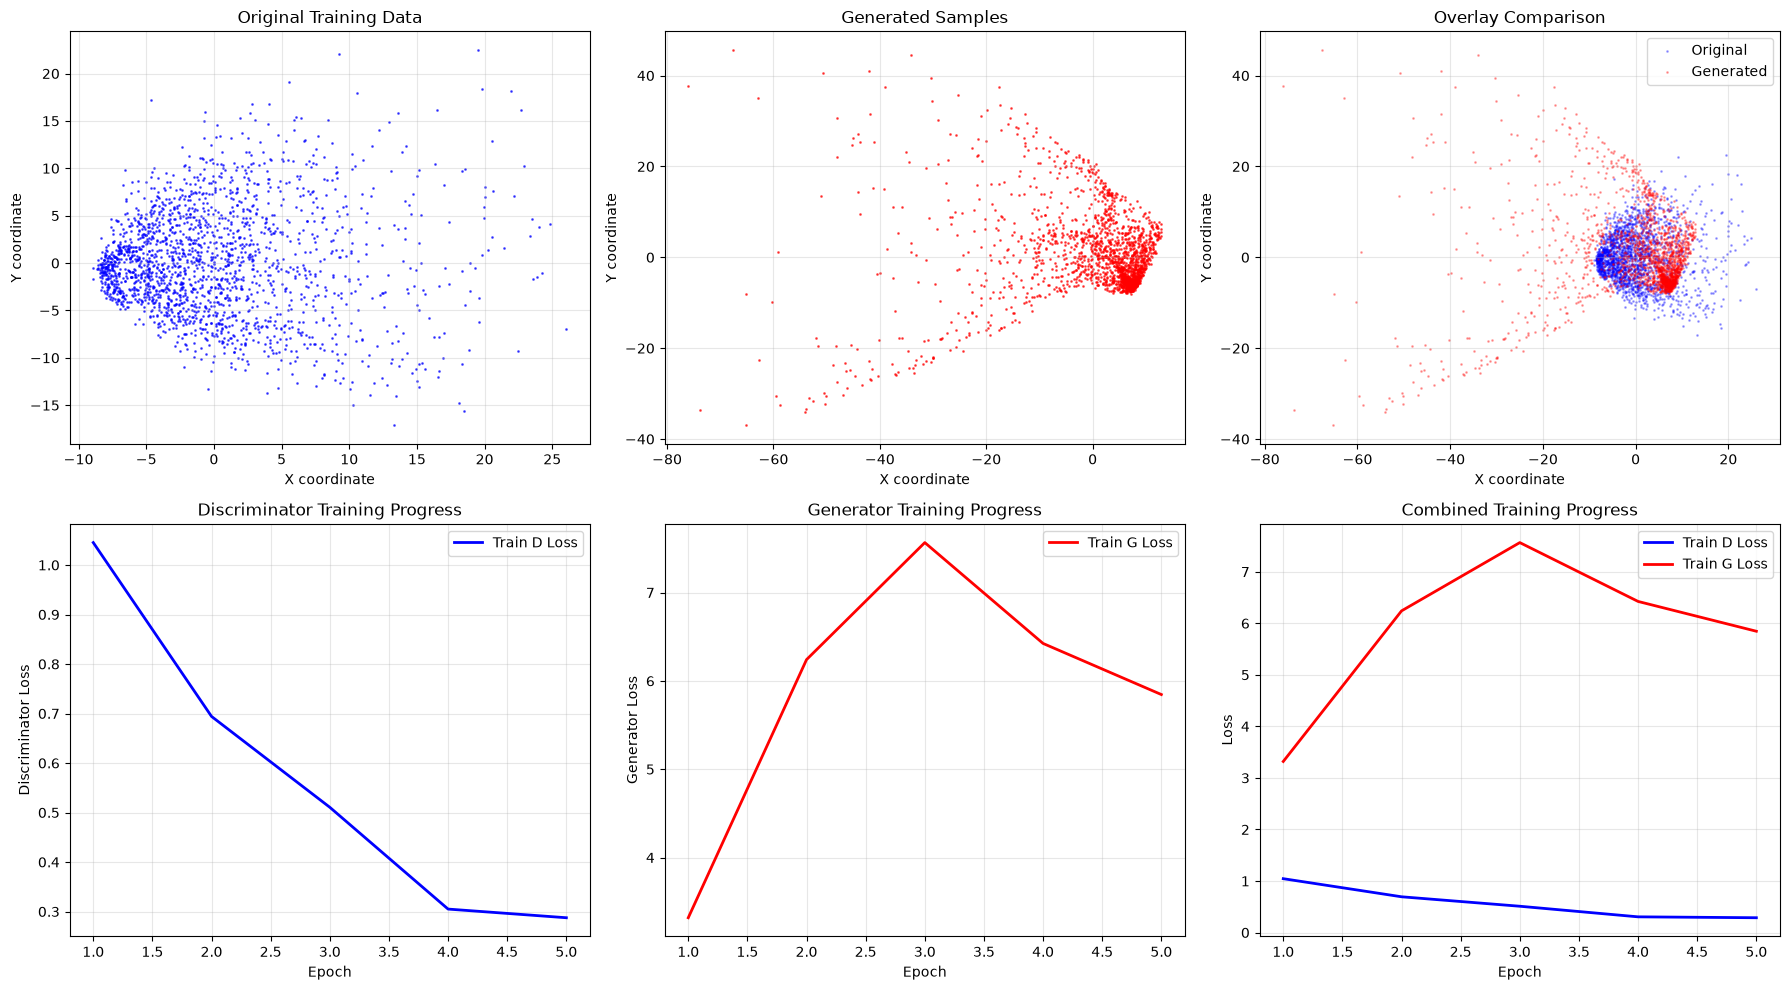

📈 Epoch 5 Summary:
   Train D Loss: 0.2875, Val D Loss: 0.1659
   Train G Loss: 5.8456, Val G Loss: 3.9865

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 0.143817	G_loss: 4.919544
Epoch: 6 [6400/60000 (11%)]	D_loss: 0.187517	G_loss: 5.507014
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.063468	G_loss: 4.293511
Epoch: 6 [19200/60000 (32%)]	D_loss: 0.352602	G_loss: 5.054650
Epoch: 6 [25600/60000 (43%)]	D_loss: 0.218369	G_loss: 4.271960
Epoch: 6 [32000/60000 (53%)]	D_loss: 0.304419	G_loss: 4.467283
Epoch: 6 [38400/60000 (64%)]	D_loss: 0.237479	G_loss: 5.222984
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.107074	G_loss: 5.061298
Epoch: 6 [51200/60000 (85%)]	D_loss: 0.159447	G_loss: 3.570376
Epoch: 6 [57600/60000 (96%)]	D_loss: 2.210583	G_loss: 3.277506
====> Epoch: 6 Train D_loss: 0.2990, Train G_loss: 5.2718
====> Epoch: 6 Val D_loss: 0.3199, Val G_loss: 5.4202
📈 Epoch 6 Summary:
   Train D Loss: 0.2990, Val D Loss: 0.3199
   Train G Loss: 5.2718, Val G Loss: 5

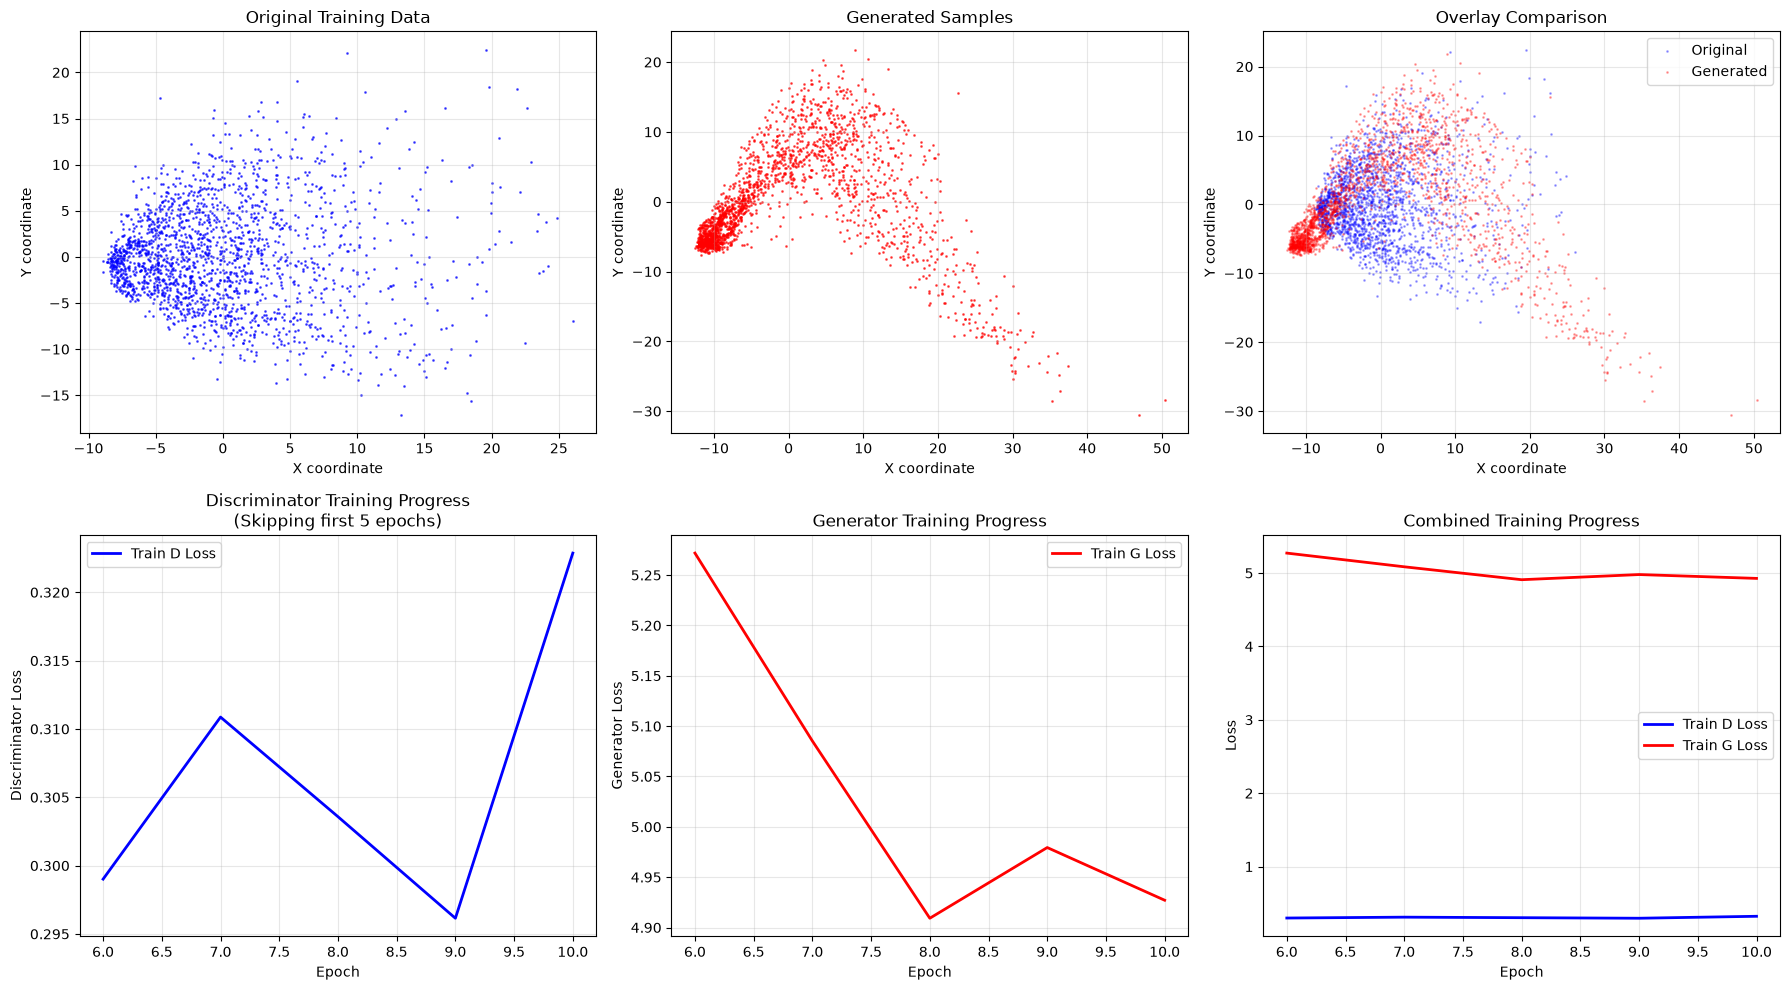

📈 Epoch 10 Summary:
   Train D Loss: 0.3229, Val D Loss: 0.1371
   Train G Loss: 4.9271, Val G Loss: 2.9303

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 0.118823	G_loss: 3.635307
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.190116	G_loss: 4.627615
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.248736	G_loss: 5.837405
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.747900	G_loss: 6.231515
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.067926	G_loss: 5.242586
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.297969	G_loss: 4.585521
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.224518	G_loss: 7.238825
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.338508	G_loss: 3.205906
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.178592	G_loss: 8.589121
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.488114	G_loss: 5.869627
====> Epoch: 11 Train D_loss: 0.2857, Train G_loss: 5.1361
====> Epoch: 11 Val D_loss: 0.1789, Val G_loss: 6.5507
📈 Epoch 11 Summary:
   Train D Loss: 0.2857, Val D Loss: 0.1789
   Train G Loss: 5.1361

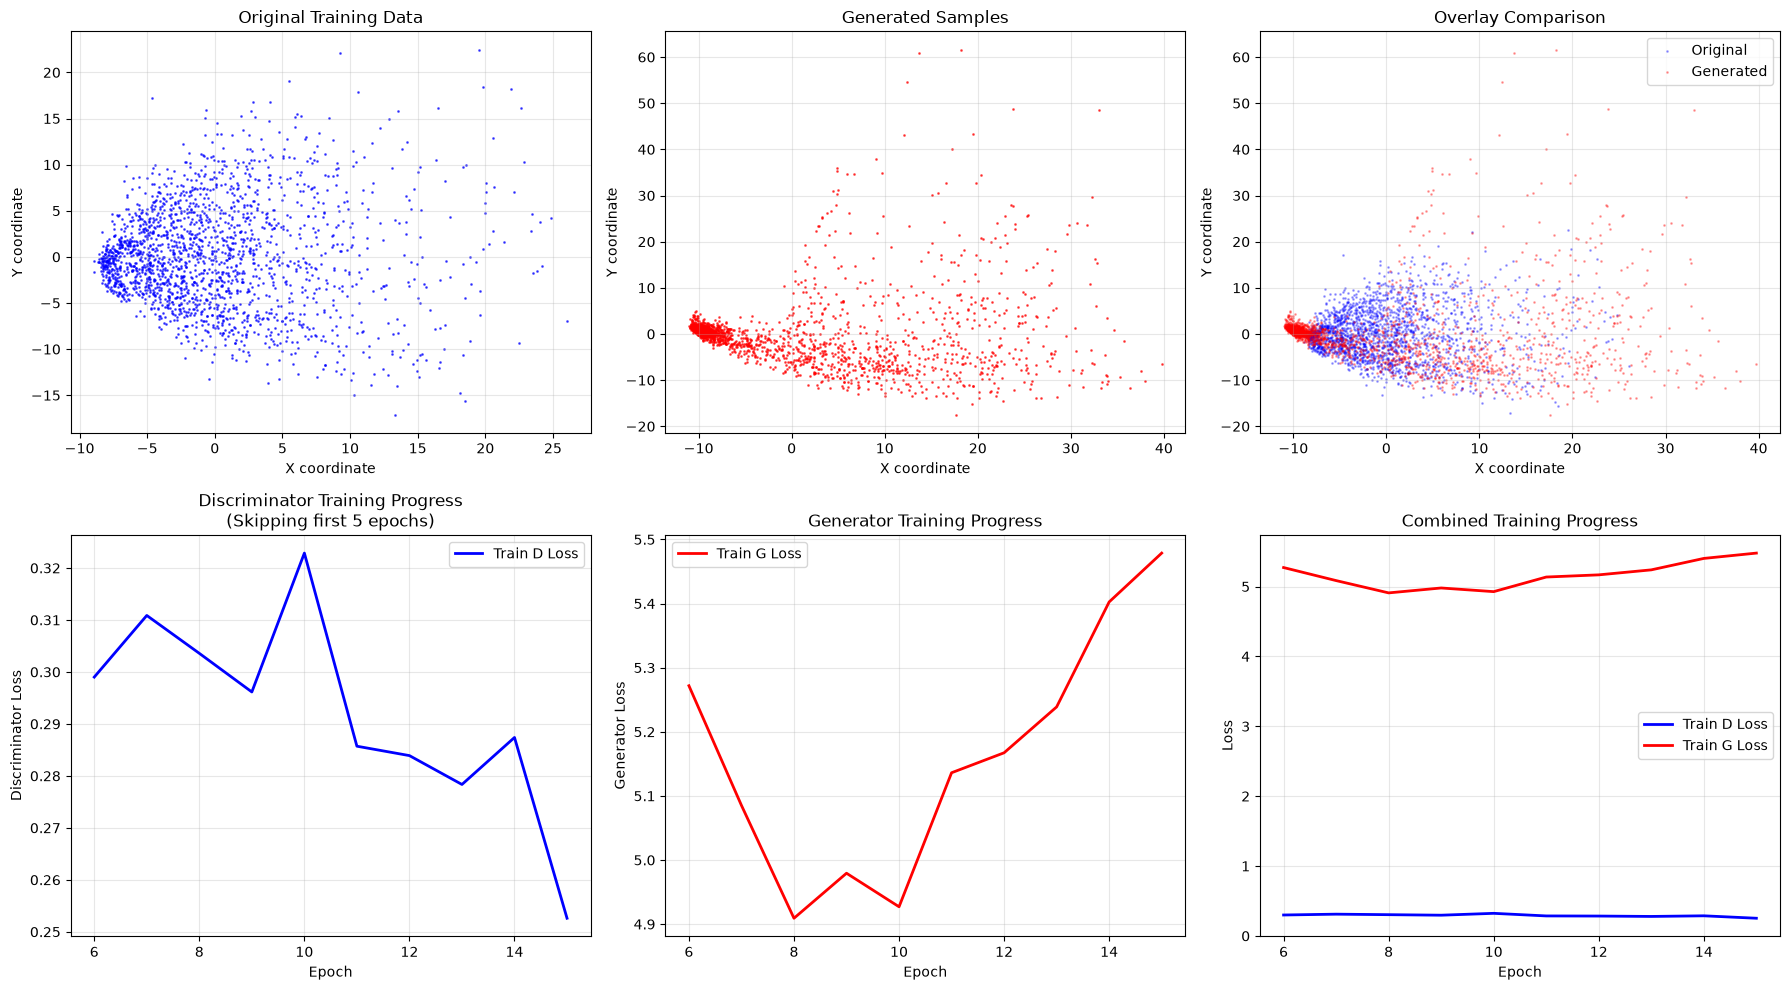

📈 Epoch 15 Summary:
   Train D Loss: 0.2526, Val D Loss: 0.1812
   Train G Loss: 5.4787, Val G Loss: 4.9358

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.229239	G_loss: 5.330256
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.296334	G_loss: 4.662102
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.159567	G_loss: 5.332671
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.468741	G_loss: 4.858478
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.150222	G_loss: 4.334630
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.103137	G_loss: 5.487724
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.166712	G_loss: 6.152241
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.321509	G_loss: 3.659273
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.343261	G_loss: 4.705855
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.376936	G_loss: 5.024800
====> Epoch: 16 Train D_loss: 0.2633, Train G_loss: 5.5693
====> Epoch: 16 Val D_loss: 0.1217, Val G_loss: 8.0385
📈 Epoch 16 Summary:
   Train D Loss: 0.2633, Val D Loss: 0.1217
   Train G Loss: 5.5693

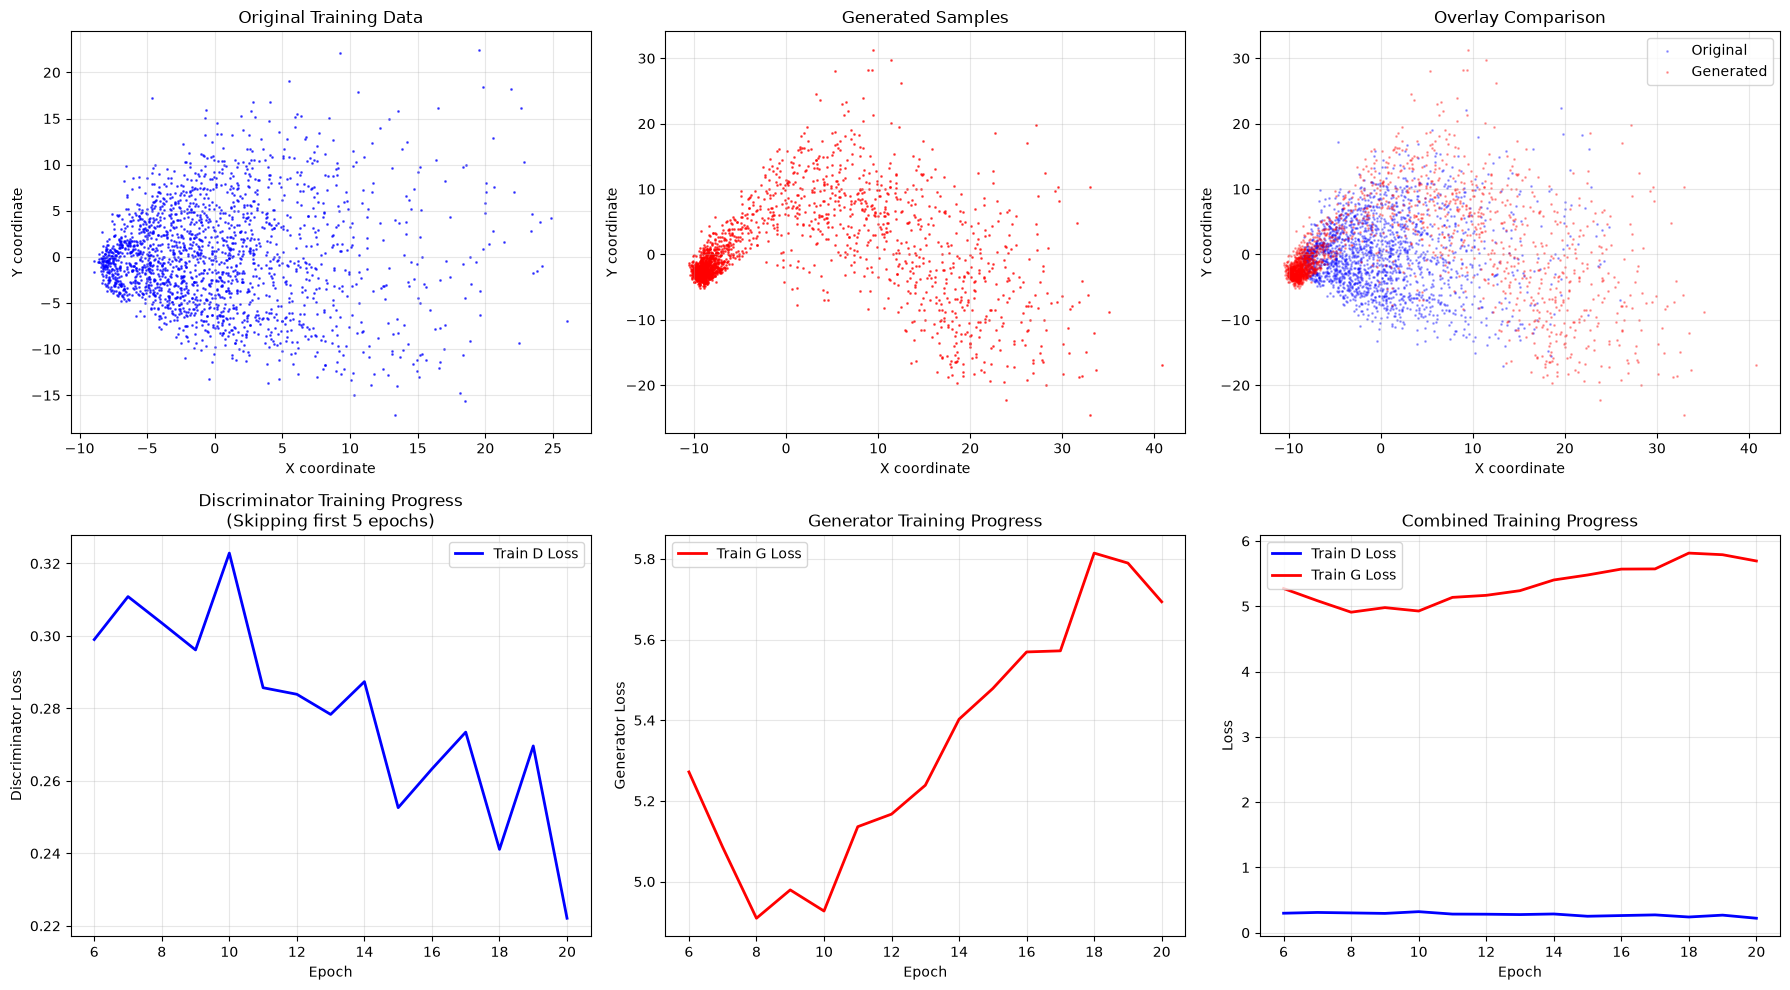

📈 Epoch 20 Summary:
   Train D Loss: 0.2221, Val D Loss: 0.2736
   Train G Loss: 5.6936, Val G Loss: 3.9694

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.225046	G_loss: 5.428876
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.222936	G_loss: 6.178534
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.328013	G_loss: 6.945694
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.313706	G_loss: 3.627072
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.212505	G_loss: 5.668253
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.229459	G_loss: 4.368604
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.320395	G_loss: 5.626150
Epoch: 21 [44800/60000 (75%)]	D_loss: 1.045905	G_loss: 7.157501
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.159124	G_loss: 4.681767
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.164708	G_loss: 3.976787
====> Epoch: 21 Train D_loss: 0.2178, Train G_loss: 5.9133
====> Epoch: 21 Val D_loss: 0.2715, Val G_loss: 4.8115
📈 Epoch 21 Summary:
   Train D Loss: 0.2178, Val D Loss: 0.2715
   Train G Loss: 5.9133

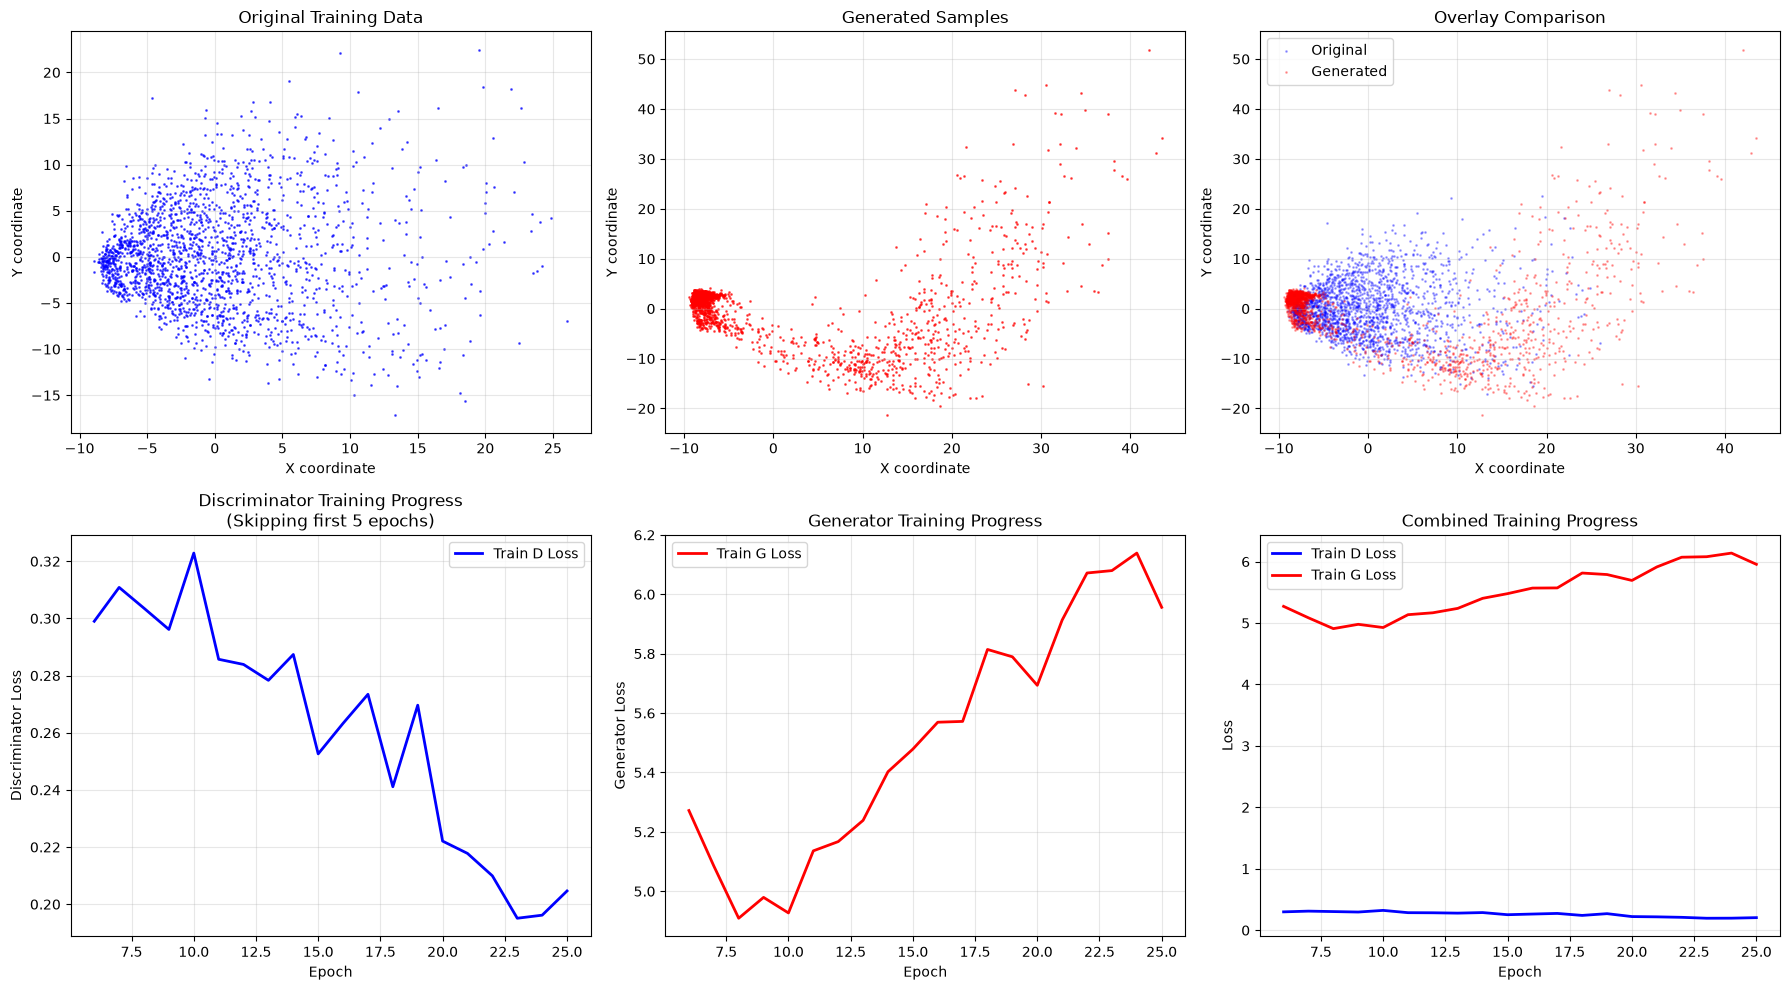

📈 Epoch 25 Summary:
   Train D Loss: 0.2046, Val D Loss: 0.2889
   Train G Loss: 5.9562, Val G Loss: 4.6347

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.182162	G_loss: 6.553713
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.186005	G_loss: 4.663626
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.261558	G_loss: 4.284885
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.249402	G_loss: 5.085649
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.163368	G_loss: 5.433706
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.195713	G_loss: 5.618090
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.413052	G_loss: 7.553027
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.235429	G_loss: 9.425543
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.290169	G_loss: 6.878794
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.080096	G_loss: 7.227172
====> Epoch: 26 Train D_loss: 0.1841, Train G_loss: 6.1668
====> Epoch: 26 Val D_loss: 0.2393, Val G_loss: 7.4920
📈 Epoch 26 Summary:
   Train D Loss: 0.1841, Val D Loss: 0.2393
   Train G Loss: 6.1668

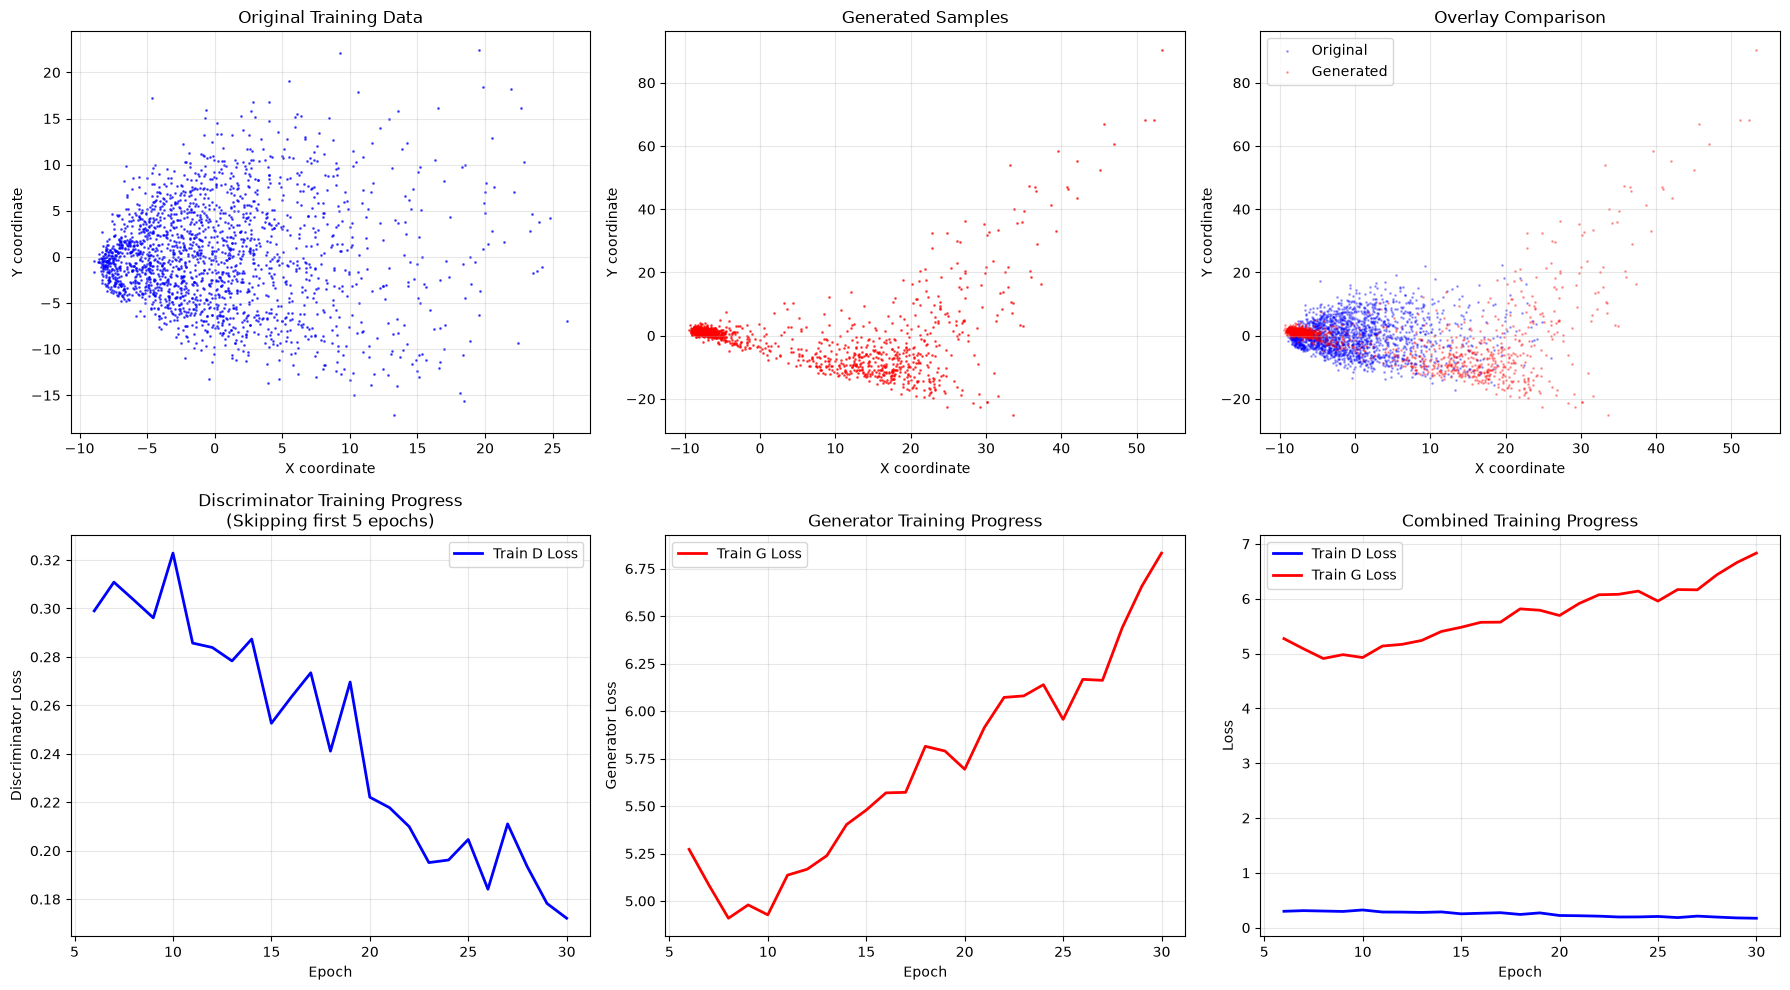

📈 Epoch 30 Summary:
   Train D Loss: 0.1721, Val D Loss: 0.2256
   Train G Loss: 6.8316, Val G Loss: 4.5292

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.199435	G_loss: 6.131697
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.175694	G_loss: 8.644801
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.091138	G_loss: 8.295959
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.116631	G_loss: 5.202049
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.130148	G_loss: 5.959695
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.093349	G_loss: 8.476434
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.060781	G_loss: 9.065544
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.128753	G_loss: 6.348770
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.175658	G_loss: 5.990204
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.326849	G_loss: 6.607110
====> Epoch: 31 Train D_loss: 0.1686, Train G_loss: 7.0527
====> Epoch: 31 Val D_loss: 0.1733, Val G_loss: 5.2849
📈 Epoch 31 Summary:
   Train D Loss: 0.1686, Val D Loss: 0.1733
   Train G Loss: 7.0527

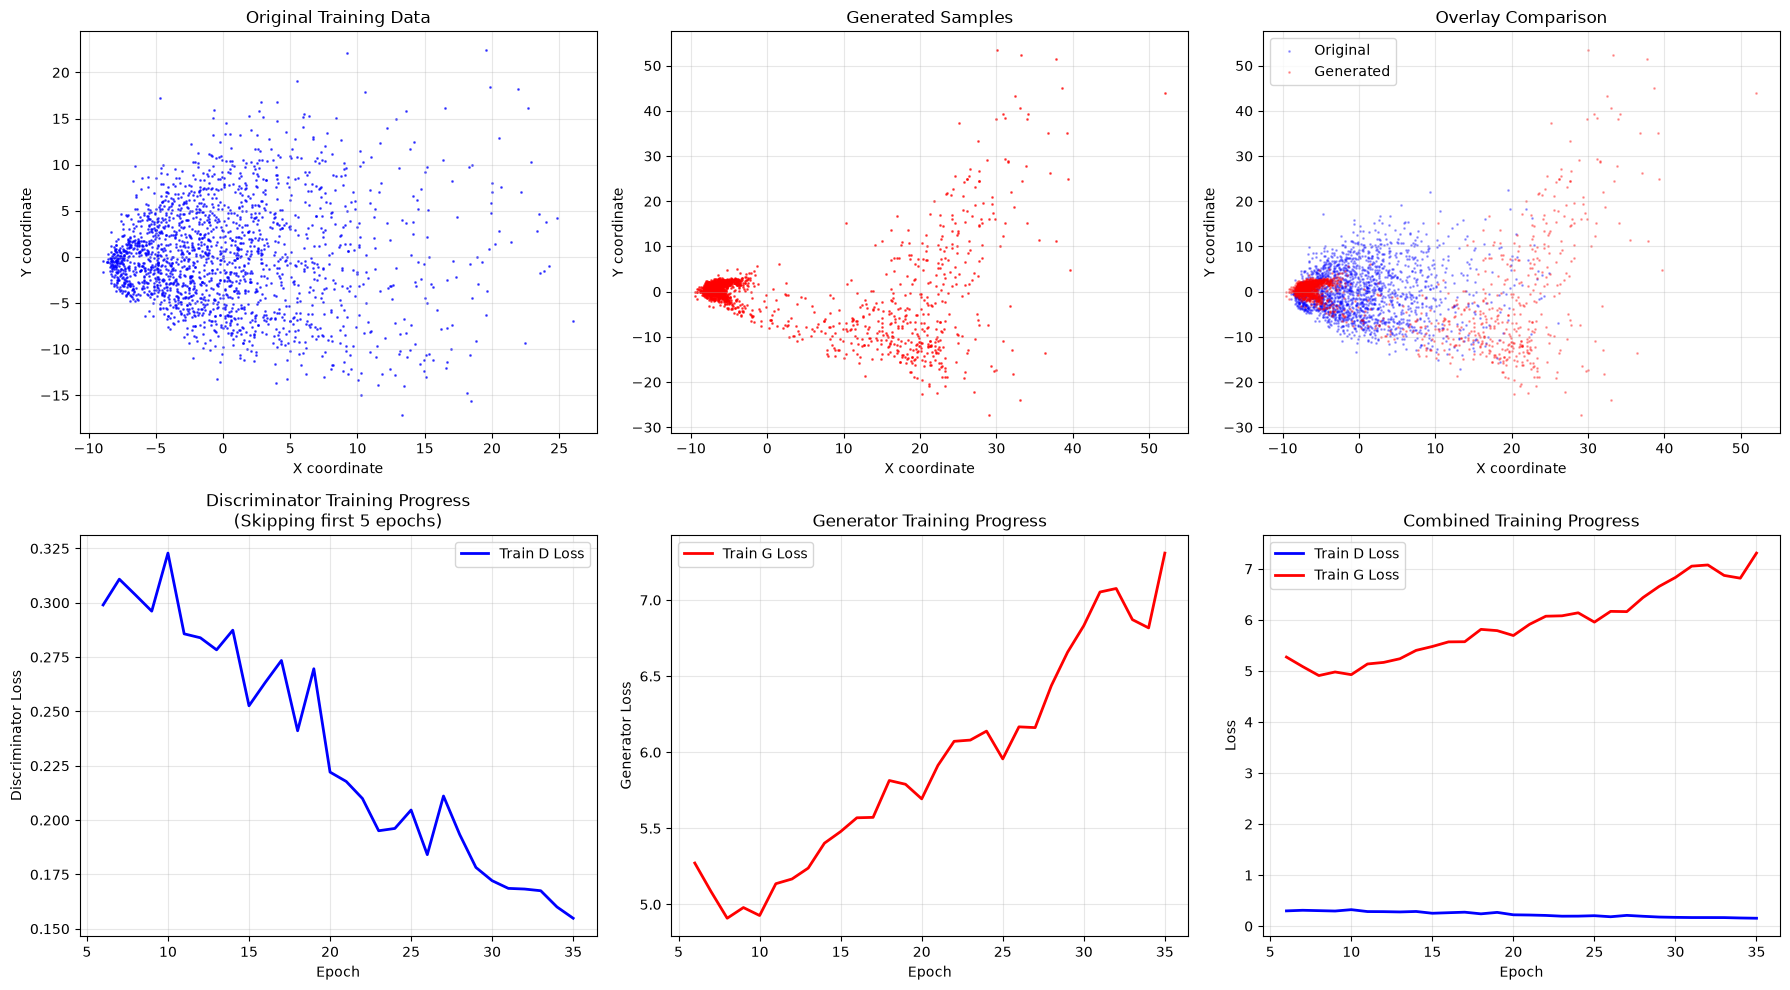

📈 Epoch 35 Summary:
   Train D Loss: 0.1548, Val D Loss: 0.2281
   Train G Loss: 7.3085, Val G Loss: 4.1608

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.162900	G_loss: 6.515907
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.128251	G_loss: 6.406699
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.190838	G_loss: 8.226542
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.225701	G_loss: 10.121655
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.527175	G_loss: 10.308484
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.149714	G_loss: 6.566229
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.113253	G_loss: 5.778506
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.073158	G_loss: 7.976274
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.131130	G_loss: 6.450357
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.117375	G_loss: 4.994826
====> Epoch: 36 Train D_loss: 0.1565, Train G_loss: 7.3095
====> Epoch: 36 Val D_loss: 0.1787, Val G_loss: 6.2841
📈 Epoch 36 Summary:
   Train D Loss: 0.1565, Val D Loss: 0.1787
   Train G Loss: 7.30

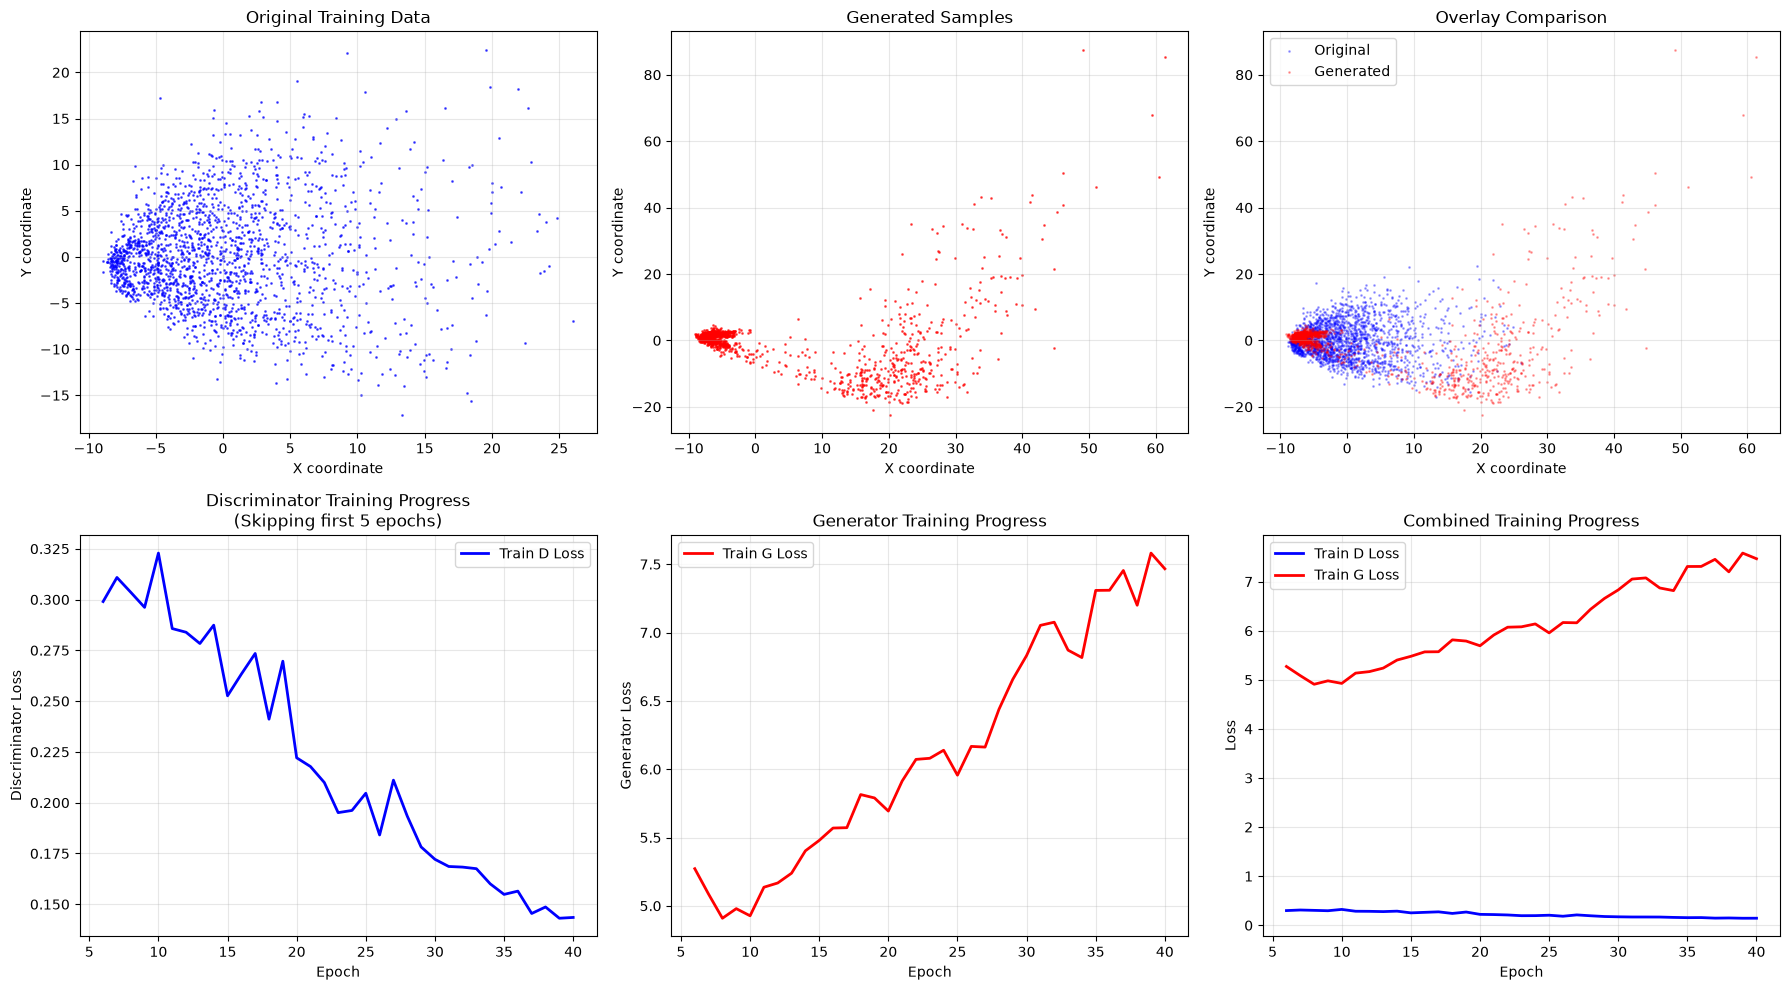

📈 Epoch 40 Summary:
   Train D Loss: 0.1435, Val D Loss: 0.1011
   Train G Loss: 7.4667, Val G Loss: 6.8438

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.100374	G_loss: 6.748824
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.250915	G_loss: 6.143208
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.042327	G_loss: 8.170609
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.261243	G_loss: 6.096557
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.176520	G_loss: 5.836741
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.163316	G_loss: 5.285887
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.077582	G_loss: 10.427059
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.065688	G_loss: 6.570912
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.102376	G_loss: 10.155986
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.117799	G_loss: 6.163066
====> Epoch: 41 Train D_loss: 0.1415, Train G_loss: 7.4261
====> Epoch: 41 Val D_loss: 0.1745, Val G_loss: 6.8595
📈 Epoch 41 Summary:
   Train D Loss: 0.1415, Val D Loss: 0.1745
   Train G Loss: 7.42

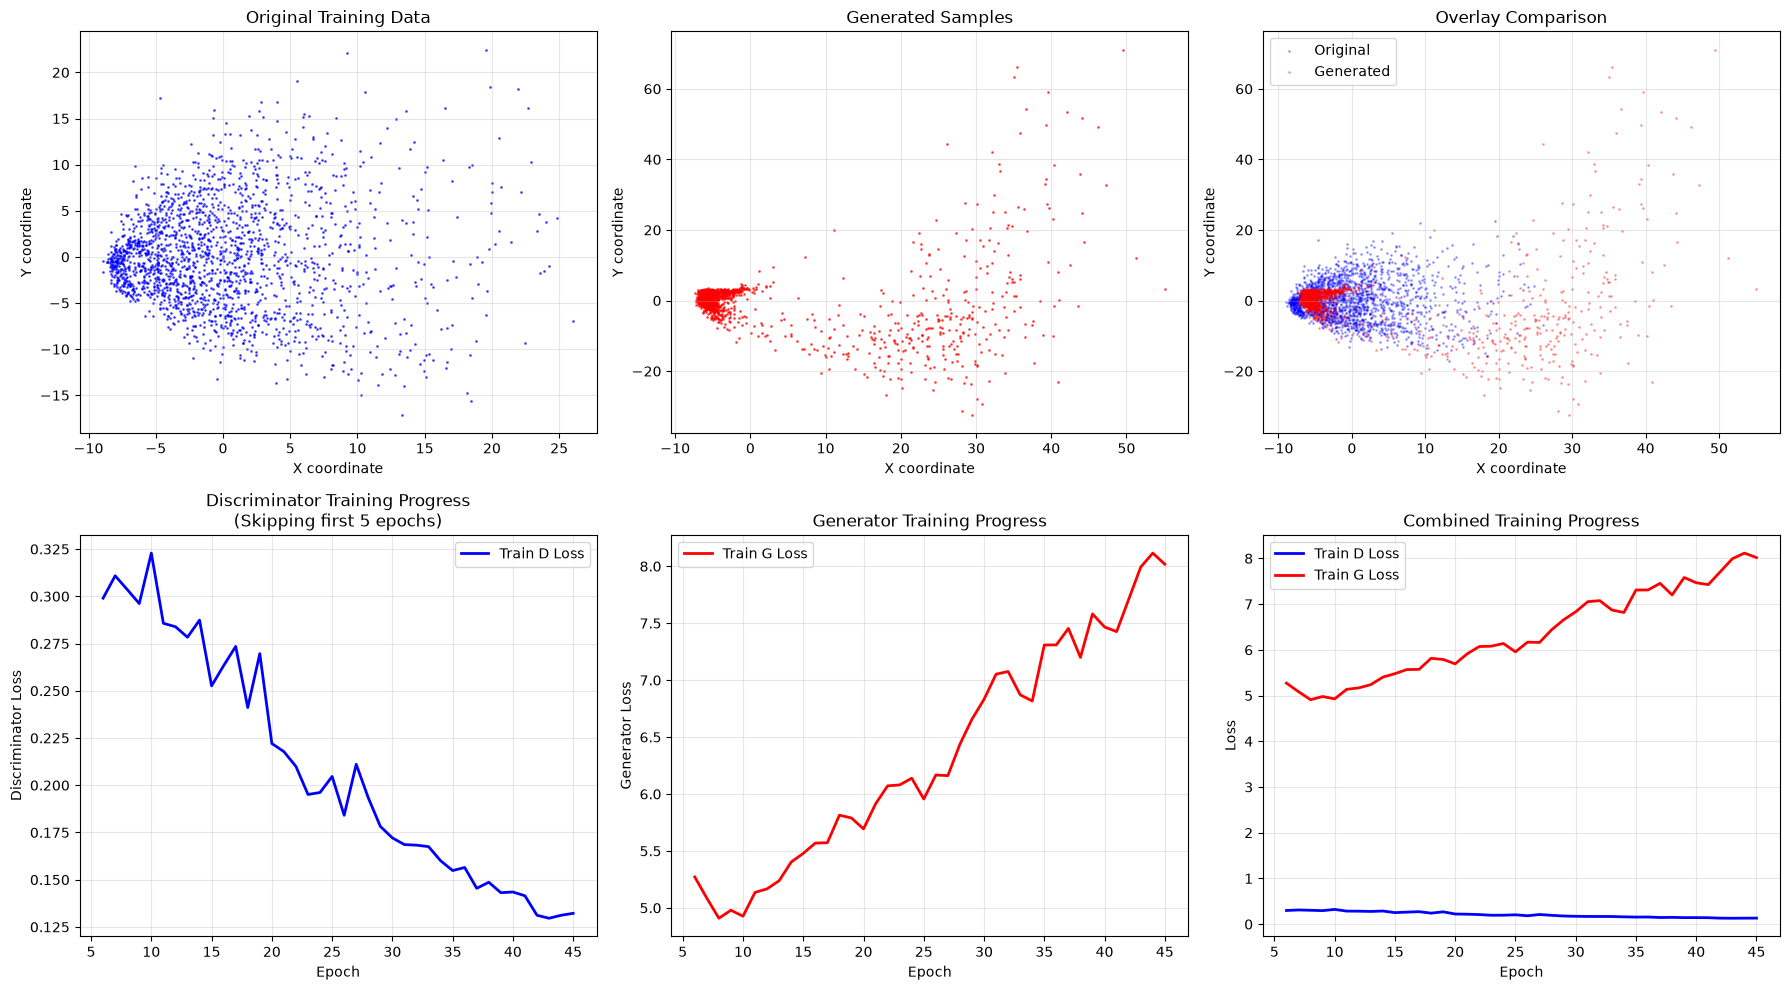

📈 Epoch 45 Summary:
   Train D Loss: 0.1322, Val D Loss: 0.1918
   Train G Loss: 8.0180, Val G Loss: 6.4674

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.089574	G_loss: 6.338229
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.060514	G_loss: 11.633713
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.059153	G_loss: 11.183450
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.068433	G_loss: 12.577780
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.024354	G_loss: 12.685835
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.099166	G_loss: 5.823967
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.143076	G_loss: 7.305875
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.446529	G_loss: 5.729685
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.278513	G_loss: 11.784542
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.076498	G_loss: 6.556929
====> Epoch: 46 Train D_loss: 0.1207, Train G_loss: 8.3953
====> Epoch: 46 Val D_loss: 0.1164, Val G_loss: 5.8391
📈 Epoch 46 Summary:
   Train D Loss: 0.1207, Val D Loss: 0.1164
   Train G Loss: 8

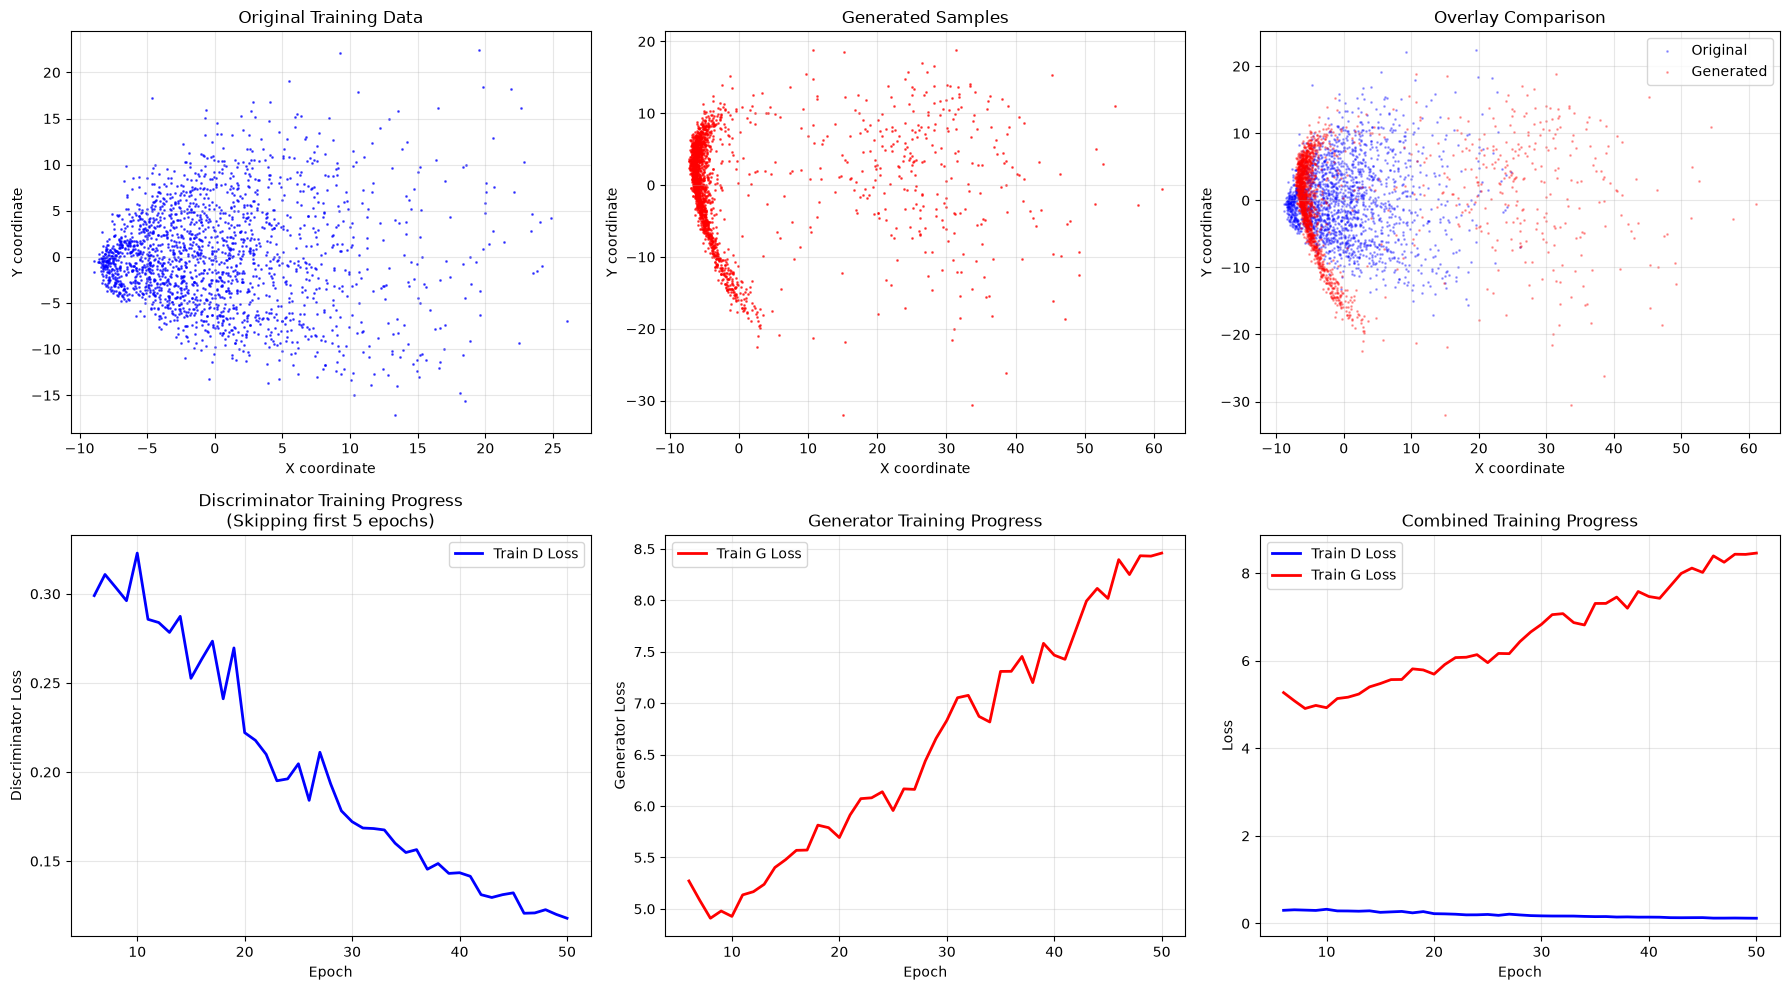

📈 Epoch 50 Summary:
   Train D Loss: 0.1180, Val D Loss: 0.1150
   Train G Loss: 8.4588, Val G Loss: 11.8962

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.086625	G_loss: 11.982390
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.110099	G_loss: 7.224846
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.074379	G_loss: 7.452529
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.219360	G_loss: 10.134194
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.139734	G_loss: 8.414414
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.104961	G_loss: 5.984332
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.042876	G_loss: 7.969452
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.105973	G_loss: 11.945919
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.029520	G_loss: 13.903980
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.079859	G_loss: 9.273428
====> Epoch: 51 Train D_loss: 0.1115, Train G_loss: 8.6415
====> Epoch: 51 Val D_loss: 0.2983, Val G_loss: 9.3880
📈 Epoch 51 Summary:
   Train D Loss: 0.1115, Val D Loss: 0.2983
   Train G Loss: 8

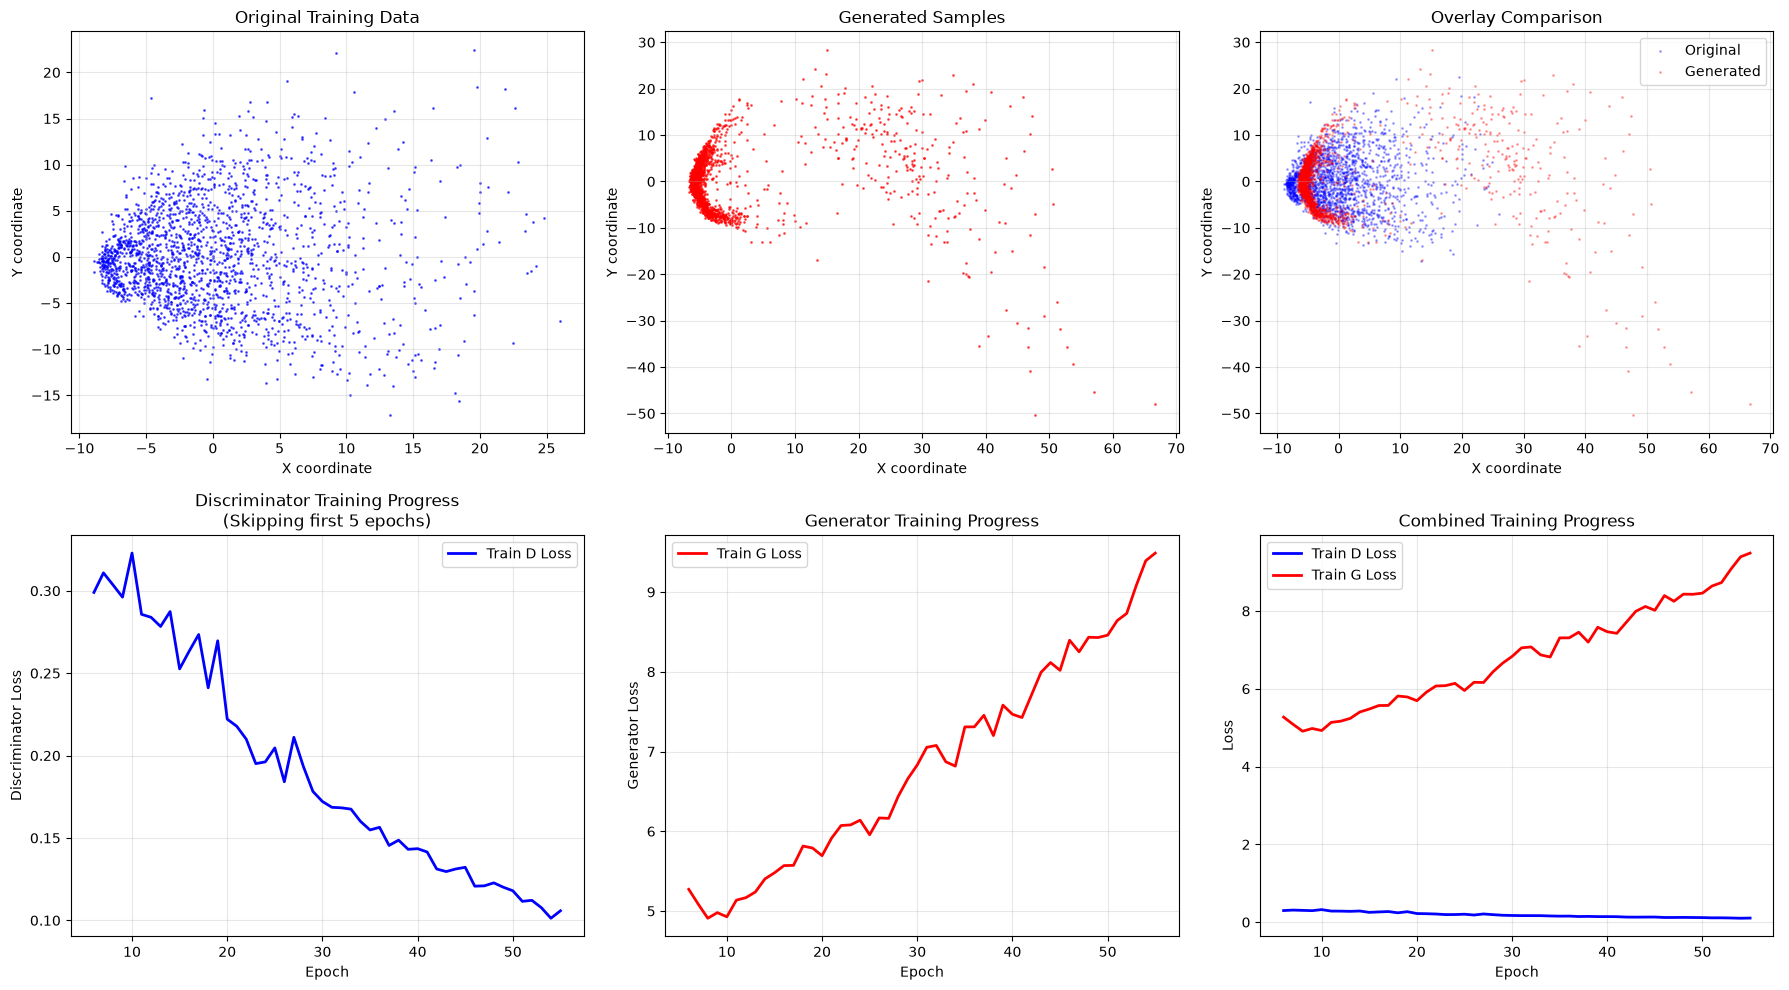

📈 Epoch 55 Summary:
   Train D Loss: 0.1058, Val D Loss: 0.2519
   Train G Loss: 9.4882, Val G Loss: 4.0660

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.221133	G_loss: 6.895901
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.042062	G_loss: 6.800895
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.030367	G_loss: 9.073660
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.194519	G_loss: 15.544594
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.077009	G_loss: 9.474789
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.071075	G_loss: 7.928986
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.145293	G_loss: 10.023865
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.410828	G_loss: 10.804025
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.112687	G_loss: 7.157268
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.152157	G_loss: 8.634388
====> Epoch: 56 Train D_loss: 0.1028, Train G_loss: 9.0446
====> Epoch: 56 Val D_loss: 0.1161, Val G_loss: 12.5087
📈 Epoch 56 Summary:
   Train D Loss: 0.1028, Val D Loss: 0.1161
   Train G Loss: 9.

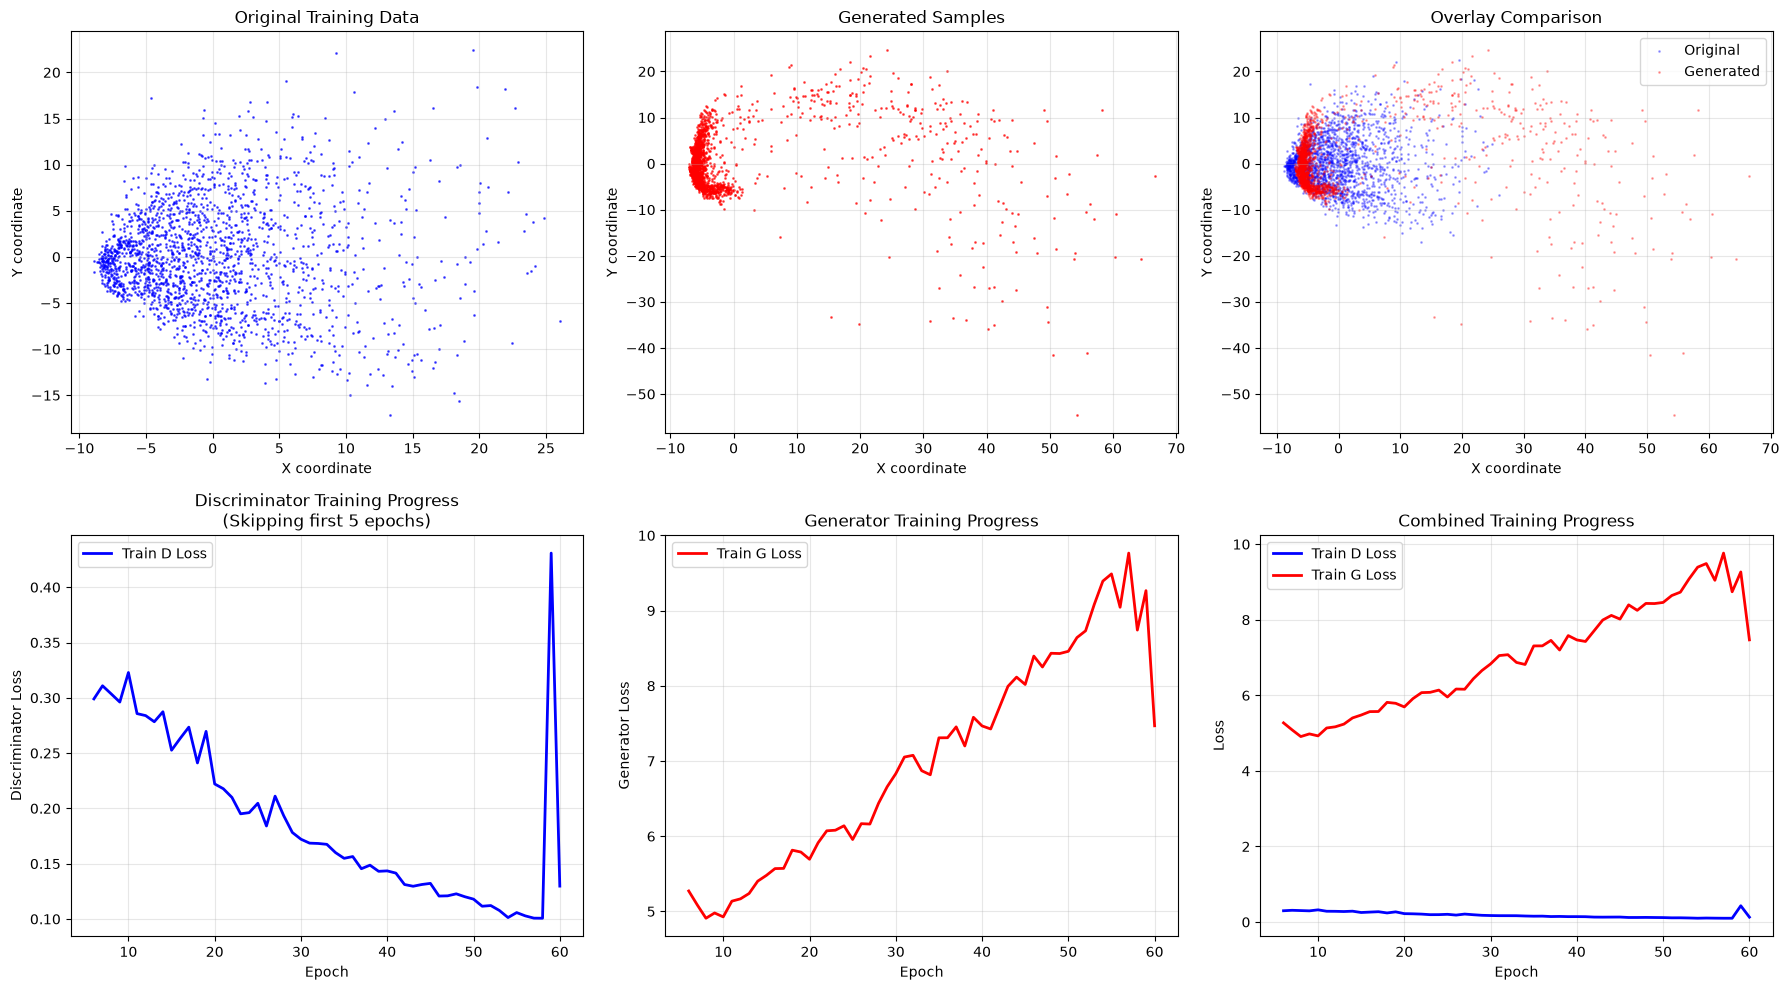

📈 Epoch 60 Summary:
   Train D Loss: 0.1297, Val D Loss: 0.1548
   Train G Loss: 7.4684, Val G Loss: 6.8385

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.135817	G_loss: 8.779412
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.147831	G_loss: 12.137634
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.058970	G_loss: 6.401703
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.087239	G_loss: 11.137371
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.072280	G_loss: 8.838785
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.123723	G_loss: 8.850983
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.069134	G_loss: 6.140783
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.034617	G_loss: 11.666264
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.038832	G_loss: 9.842821
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.101265	G_loss: 15.789453
====> Epoch: 61 Train D_loss: 0.0927, Train G_loss: 9.1831
====> Epoch: 61 Val D_loss: 0.1781, Val G_loss: 5.0344
📈 Epoch 61 Summary:
   Train D Loss: 0.0927, Val D Loss: 0.1781
   Train G Loss: 9.

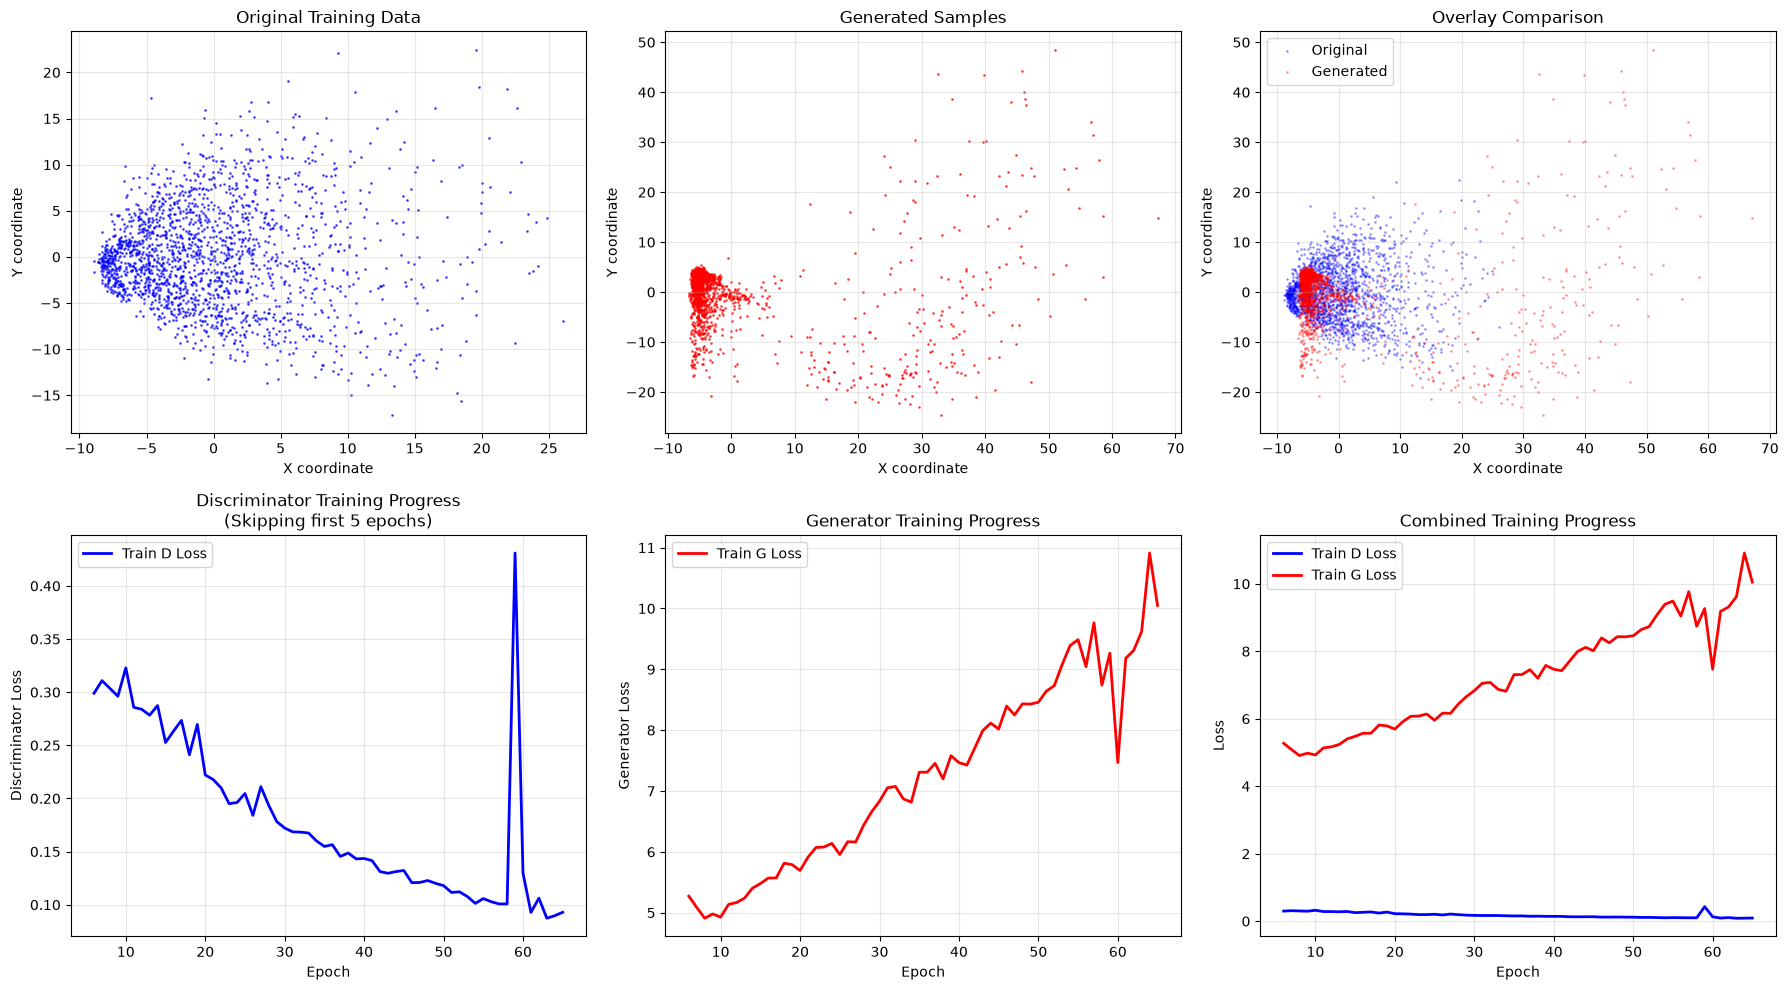

📈 Epoch 65 Summary:
   Train D Loss: 0.0929, Val D Loss: 0.1166
   Train G Loss: 10.0508, Val G Loss: 7.1818

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.138156	G_loss: 9.037082
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.053314	G_loss: 16.047234
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.050103	G_loss: 7.923727
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.275884	G_loss: 9.023108
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.078229	G_loss: 6.233259
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.100520	G_loss: 6.631856
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.027916	G_loss: 7.082696
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.062325	G_loss: 8.941162
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.071820	G_loss: 9.894293
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.017435	G_loss: 15.882511
====> Epoch: 66 Train D_loss: 0.1012, Train G_loss: 9.9626
====> Epoch: 66 Val D_loss: 0.3209, Val G_loss: 5.5716
📈 Epoch 66 Summary:
   Train D Loss: 0.1012, Val D Loss: 0.3209
   Train G Loss: 9.9

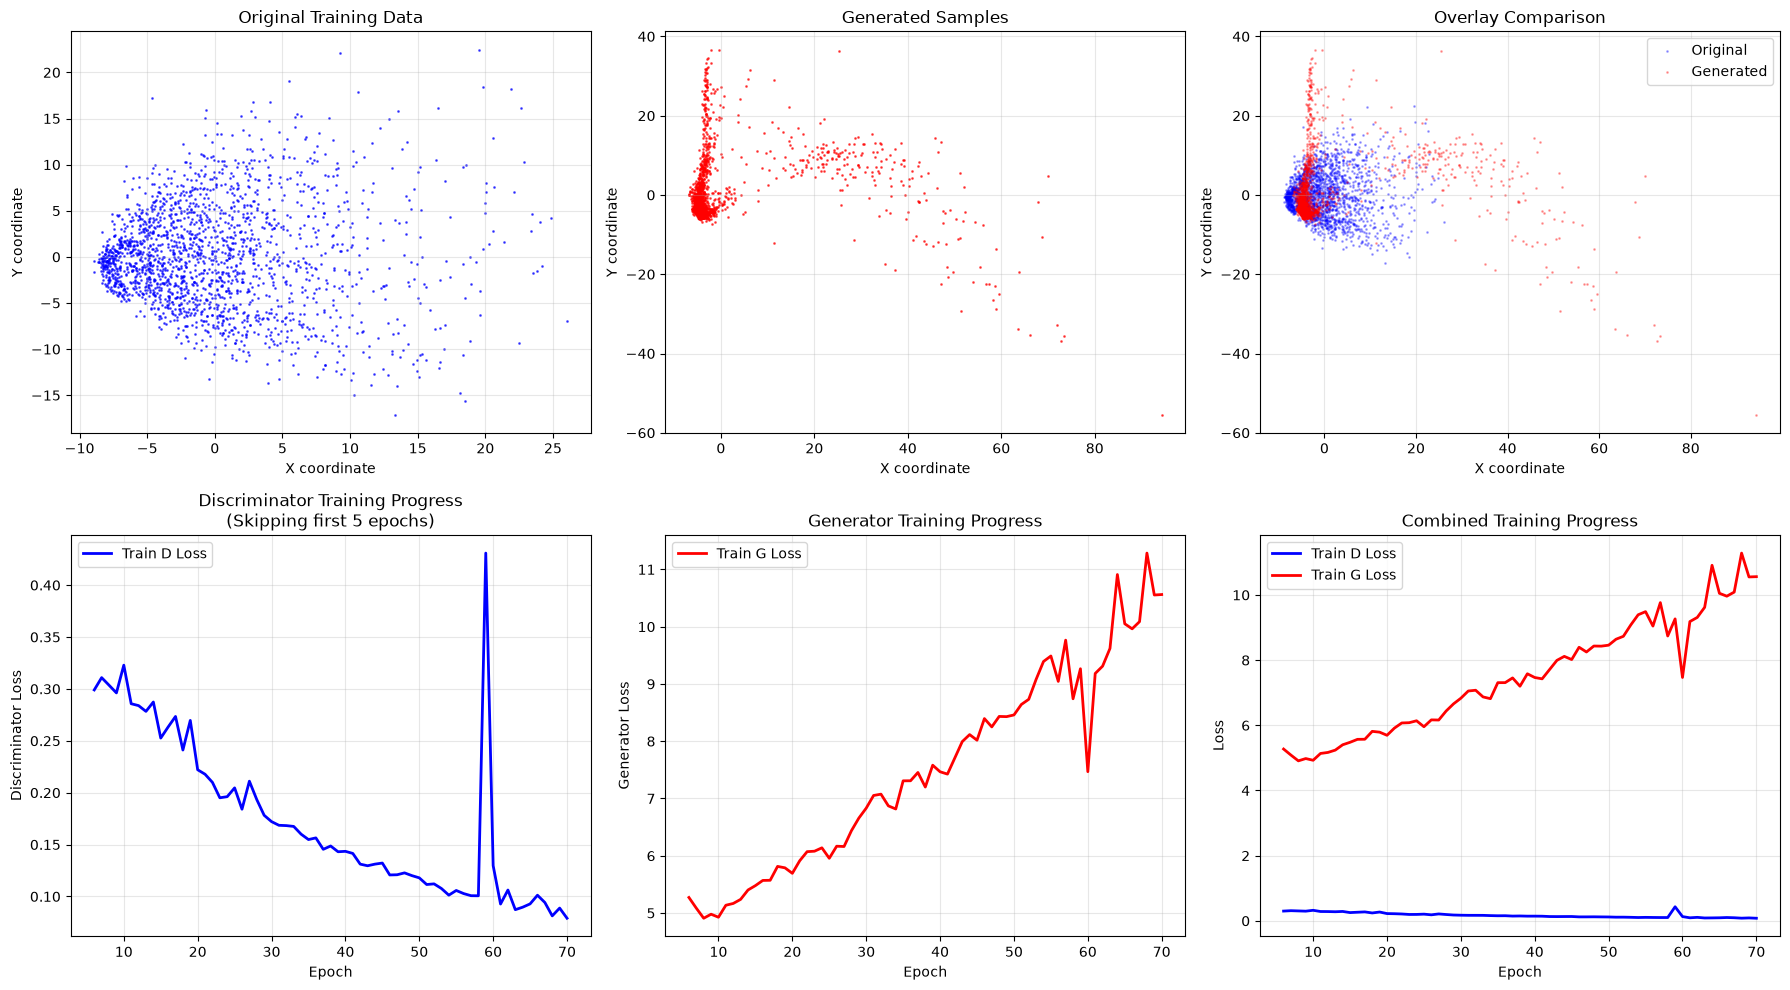

📈 Epoch 70 Summary:
   Train D Loss: 0.0790, Val D Loss: 0.1008
   Train G Loss: 10.5613, Val G Loss: 16.9266

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.090904	G_loss: 16.043793
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.292473	G_loss: 13.169817
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.614800	G_loss: 9.981730
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.199415	G_loss: 8.890345
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.061891	G_loss: 6.211269
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.114186	G_loss: 4.647259
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.056959	G_loss: 5.489618
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.026289	G_loss: 7.993976
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.045810	G_loss: 13.725401
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.091671	G_loss: 8.499955
====> Epoch: 71 Train D_loss: 0.3688, Train G_loss: 7.6015
====> Epoch: 71 Val D_loss: 0.1087, Val G_loss: 11.6064
📈 Epoch 71 Summary:
   Train D Loss: 0.3688, Val D Loss: 0.1087
   Train G Loss: 

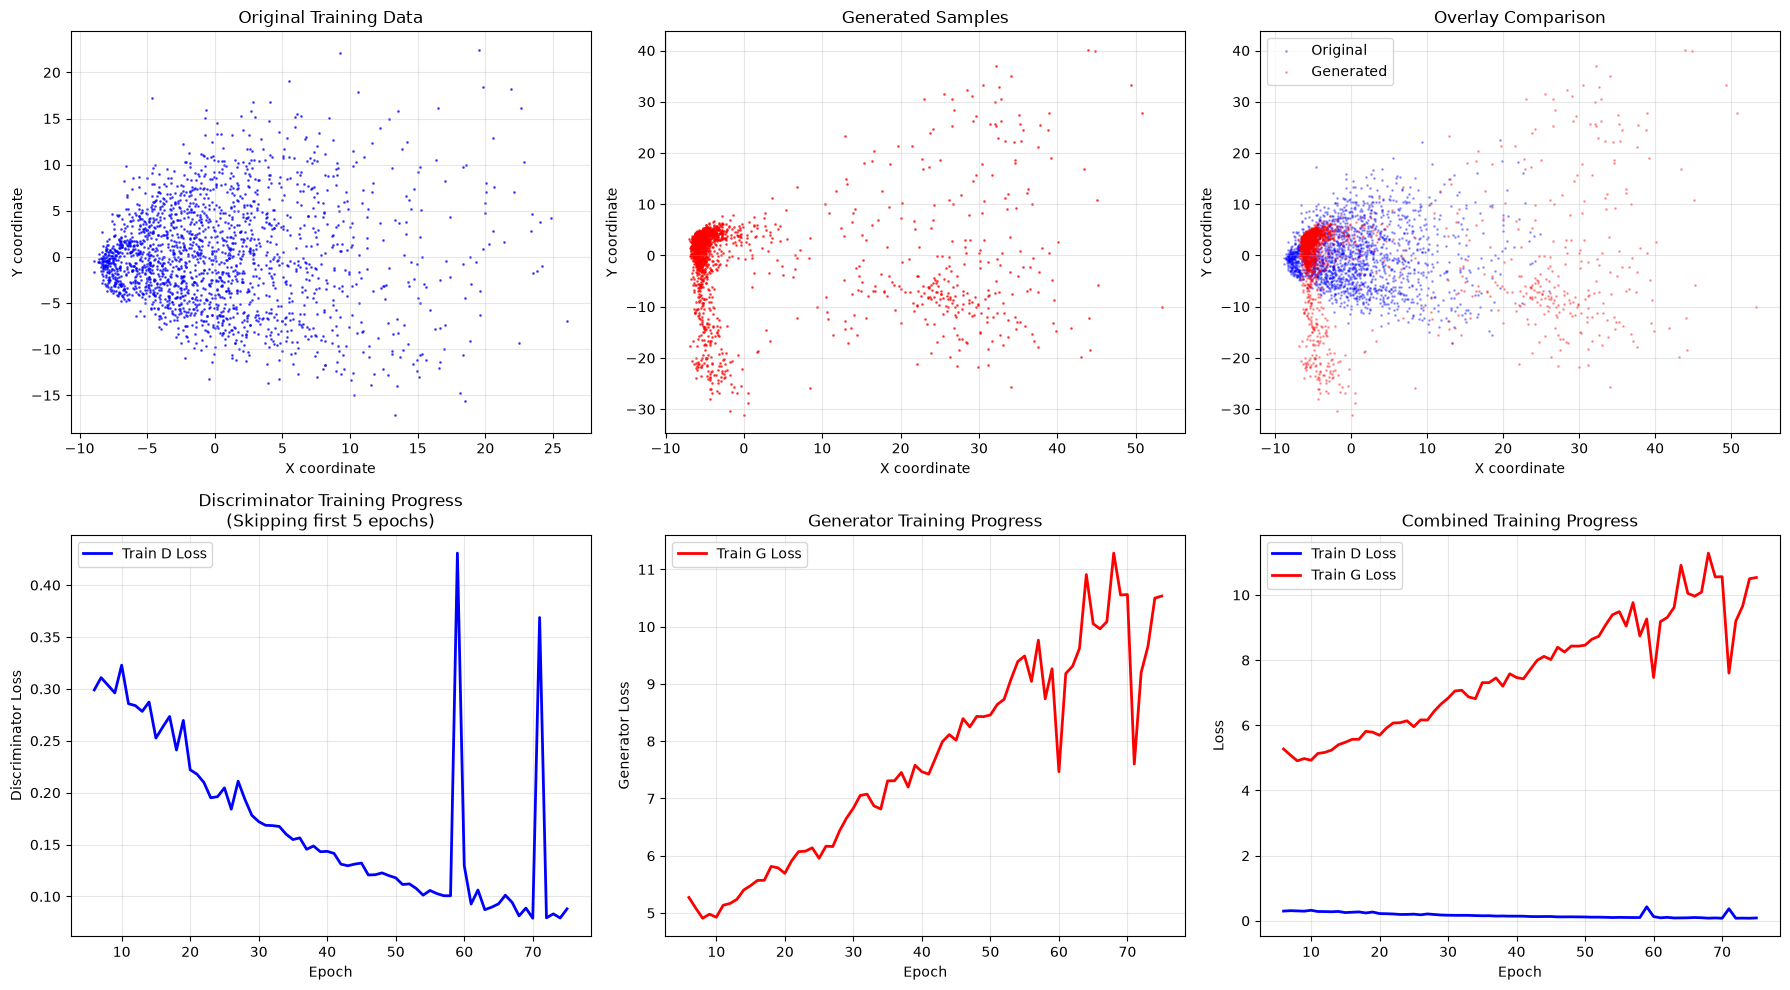

📈 Epoch 75 Summary:
   Train D Loss: 0.0881, Val D Loss: 0.0953
   Train G Loss: 10.5349, Val G Loss: 11.4940

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.064174	G_loss: 11.150942
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.068766	G_loss: 11.043470
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.112549	G_loss: 8.990425
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.126186	G_loss: 9.597983
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.105011	G_loss: 8.123095
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.048117	G_loss: 8.948458
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.050756	G_loss: 12.754762
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.093670	G_loss: 15.328342
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.150226	G_loss: 6.458848
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.102182	G_loss: 18.612692
====> Epoch: 76 Train D_loss: 0.0763, Train G_loss: 10.9483
====> Epoch: 76 Val D_loss: 0.1117, Val G_loss: 9.8971
📈 Epoch 76 Summary:
   Train D Loss: 0.0763, Val D Loss: 0.1117
   Train G Loss

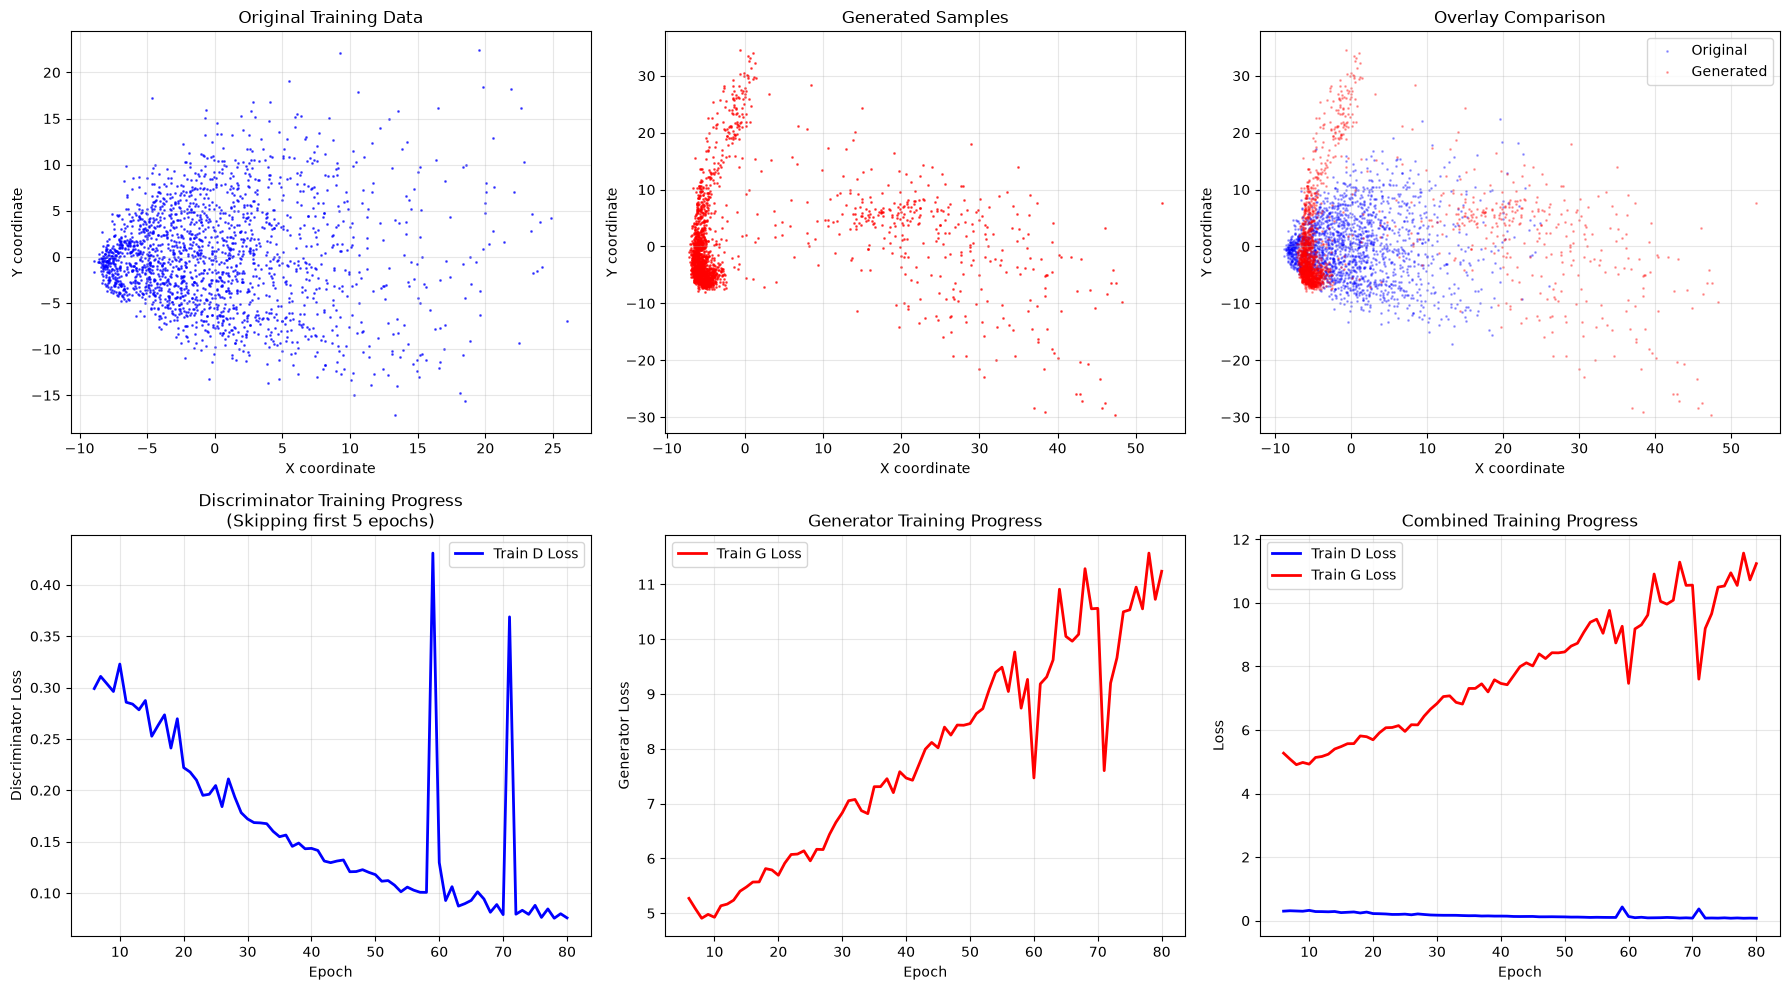

📈 Epoch 80 Summary:
   Train D Loss: 0.0759, Val D Loss: 0.1342
   Train G Loss: 11.2378, Val G Loss: 6.7720

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.134641	G_loss: 7.565324
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.017300	G_loss: 9.477382
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.052130	G_loss: 9.579171
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.008754	G_loss: 18.541054
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.097786	G_loss: 9.786907
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.037316	G_loss: 13.874409
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.071871	G_loss: 10.099500
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.211172	G_loss: 10.197540
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.030967	G_loss: 15.651330
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.044451	G_loss: 11.176629
====> Epoch: 81 Train D_loss: 0.0788, Train G_loss: 11.4494
====> Epoch: 81 Val D_loss: 0.2171, Val G_loss: 17.8256
📈 Epoch 81 Summary:
   Train D Loss: 0.0788, Val D Loss: 0.2171
   Train G Los

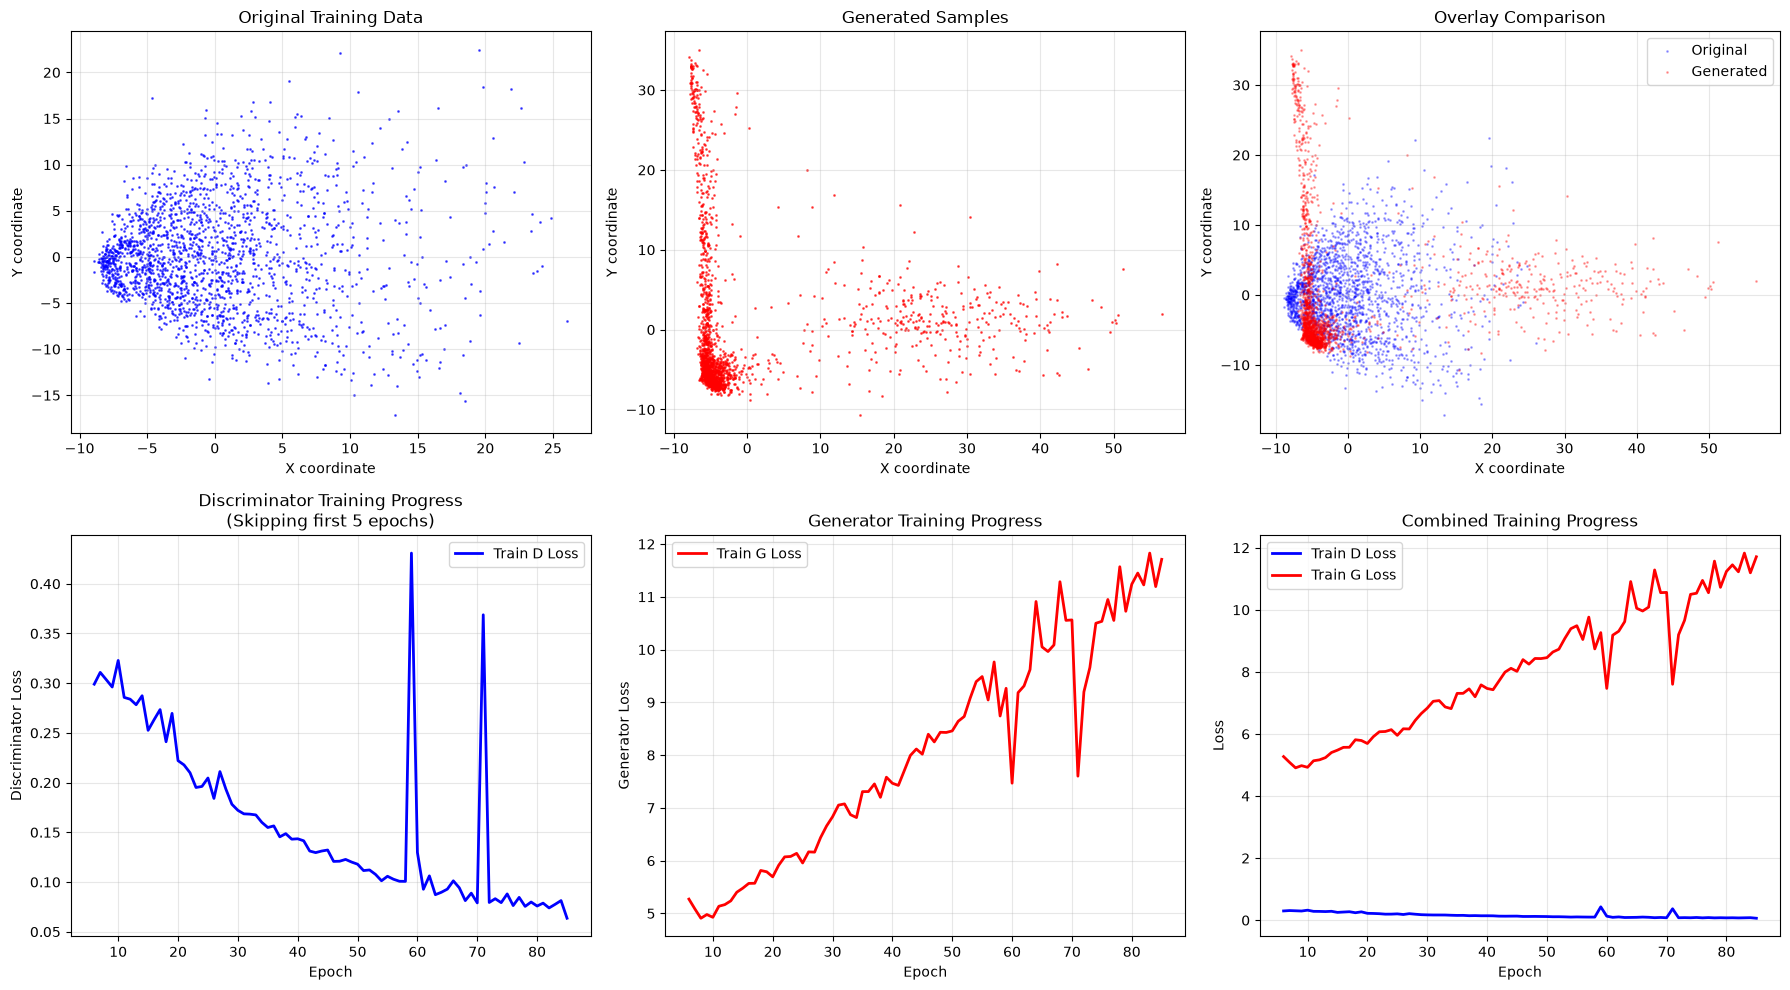

📈 Epoch 85 Summary:
   Train D Loss: 0.0636, Val D Loss: 0.0864
   Train G Loss: 11.7097, Val G Loss: 14.1001

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.055709	G_loss: 13.078732
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.176862	G_loss: 8.933216
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.114835	G_loss: 12.149145
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.032939	G_loss: 10.245790
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.028198	G_loss: 12.174728
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.066395	G_loss: 7.286583
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.147392	G_loss: 7.284636
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.222731	G_loss: 9.445383
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.093101	G_loss: 10.522352
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.067433	G_loss: 11.443980
====> Epoch: 86 Train D_loss: 0.0796, Train G_loss: 10.7615
====> Epoch: 86 Val D_loss: 0.1300, Val G_loss: 17.0027
📈 Epoch 86 Summary:
   Train D Loss: 0.0796, Val D Loss: 0.1300
   Train G Lo

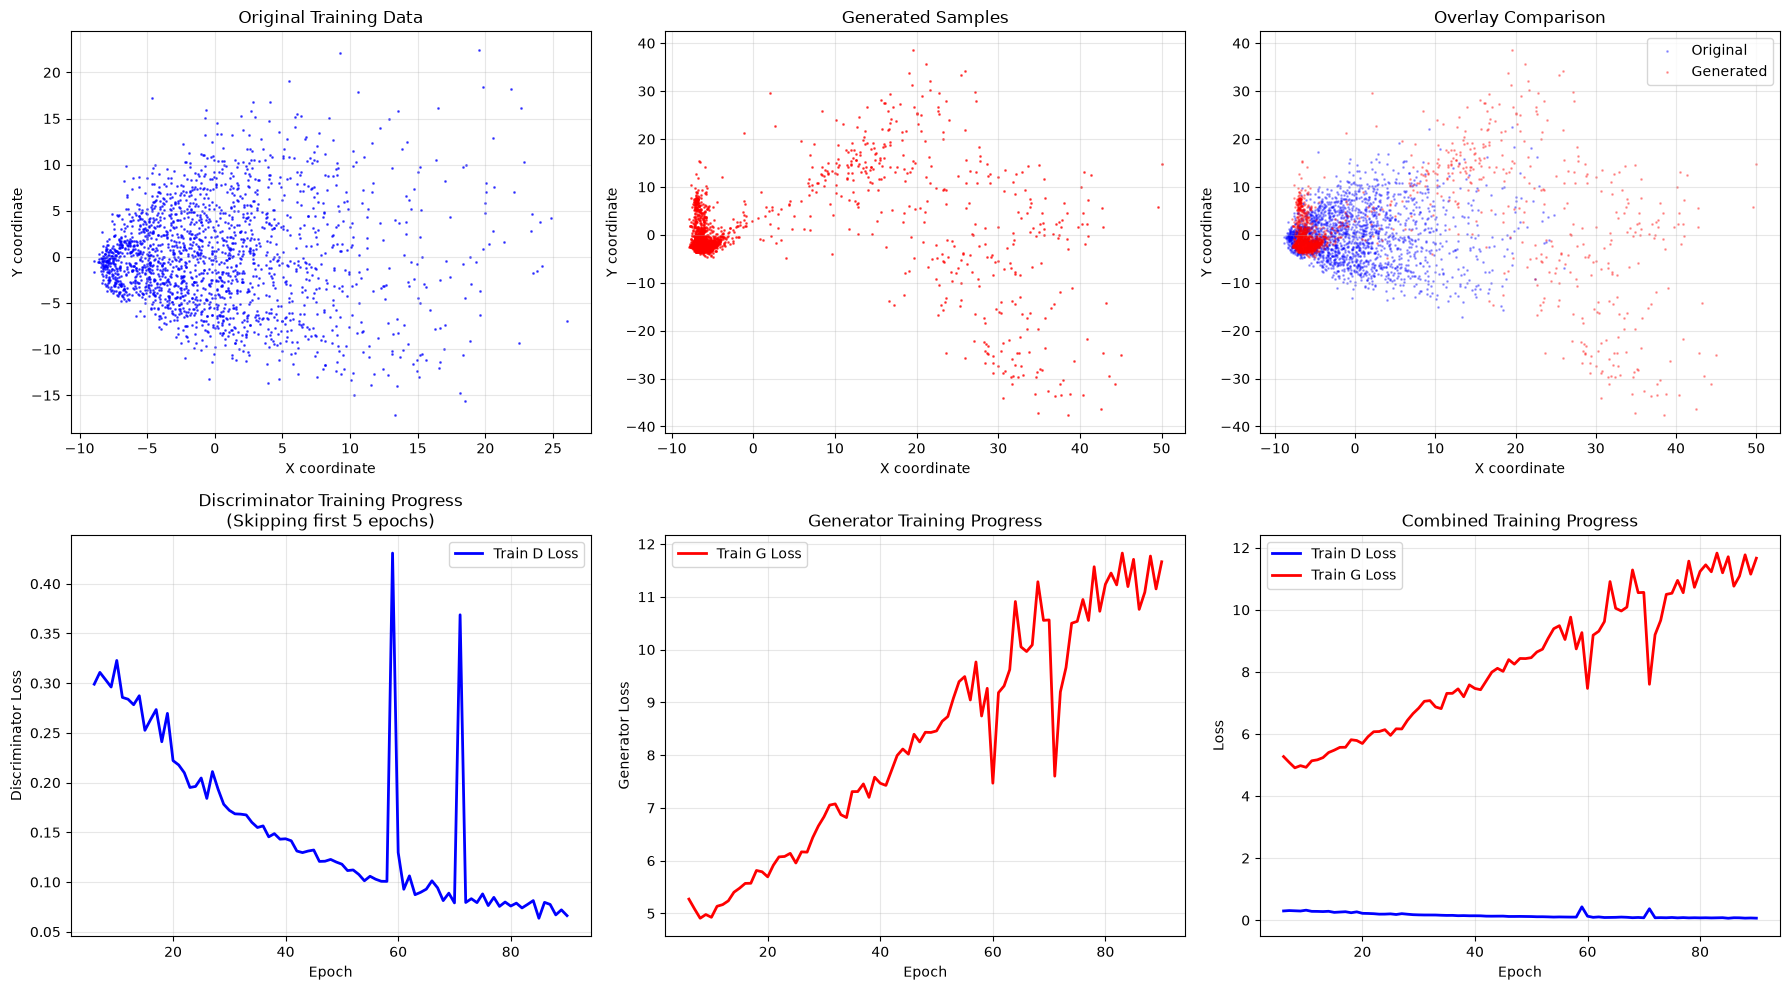

📈 Epoch 90 Summary:
   Train D Loss: 0.0662, Val D Loss: 0.0794
   Train G Loss: 11.6637, Val G Loss: 8.9228

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.073816	G_loss: 7.292973
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.158182	G_loss: 9.095901
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.022030	G_loss: 9.817006
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.109595	G_loss: 8.380341
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.054566	G_loss: 9.506529
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.448202	G_loss: 8.429215
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.185736	G_loss: 12.264292
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.052650	G_loss: 7.585333
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.006397	G_loss: 14.100864
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.123517	G_loss: 15.351479
====> Epoch: 91 Train D_loss: 0.0715, Train G_loss: 11.3338
====> Epoch: 91 Val D_loss: 0.1005, Val G_loss: 6.6167
📈 Epoch 91 Summary:
   Train D Loss: 0.0715, Val D Loss: 0.1005
   Train G Loss: 1

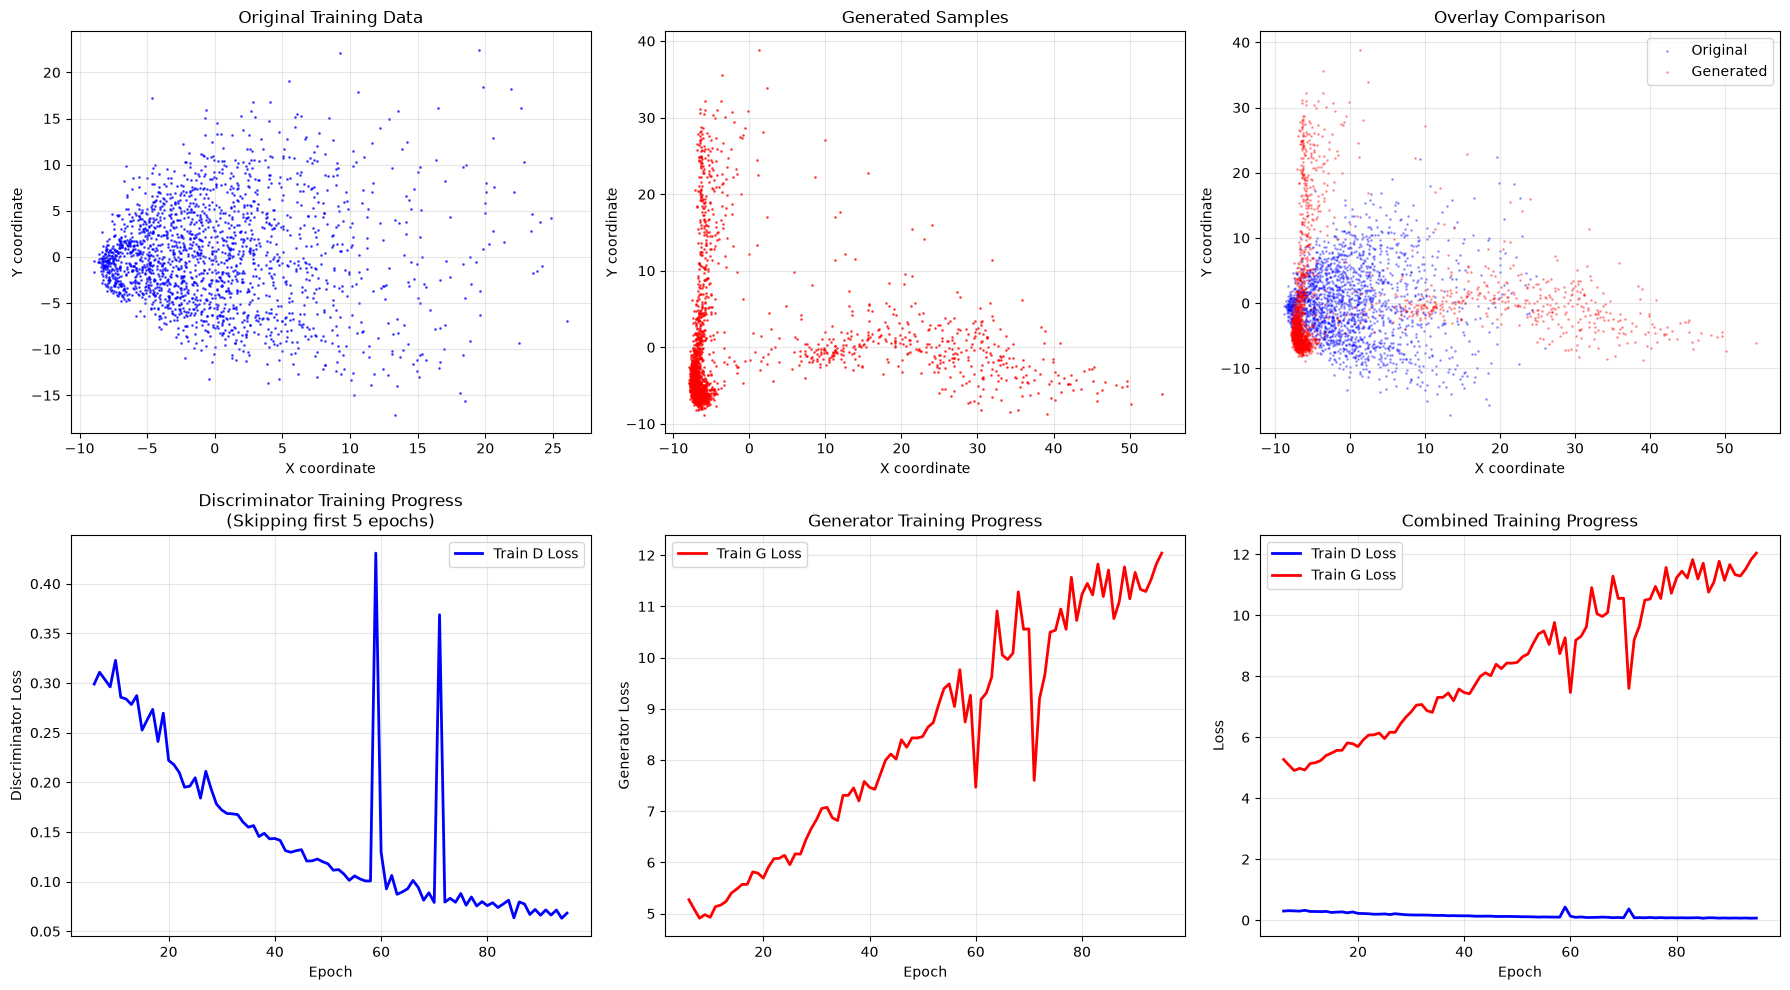

📈 Epoch 95 Summary:
   Train D Loss: 0.0683, Val D Loss: 0.0831
   Train G Loss: 12.0415, Val G Loss: 13.0553

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.051356	G_loss: 13.260251
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.020467	G_loss: 13.761961
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.101122	G_loss: 8.463378
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.083230	G_loss: 15.696535
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.041332	G_loss: 8.908657
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.116393	G_loss: 10.515497
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.084641	G_loss: 8.953038
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.122198	G_loss: 6.578888
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.053719	G_loss: 22.171734
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.056996	G_loss: 15.490215
====> Epoch: 96 Train D_loss: 0.0617, Train G_loss: 12.0713
====> Epoch: 96 Val D_loss: 0.0749, Val G_loss: 10.9648
📈 Epoch 96 Summary:
   Train D Loss: 0.0617, Val D Loss: 0.0749
   Train G Lo

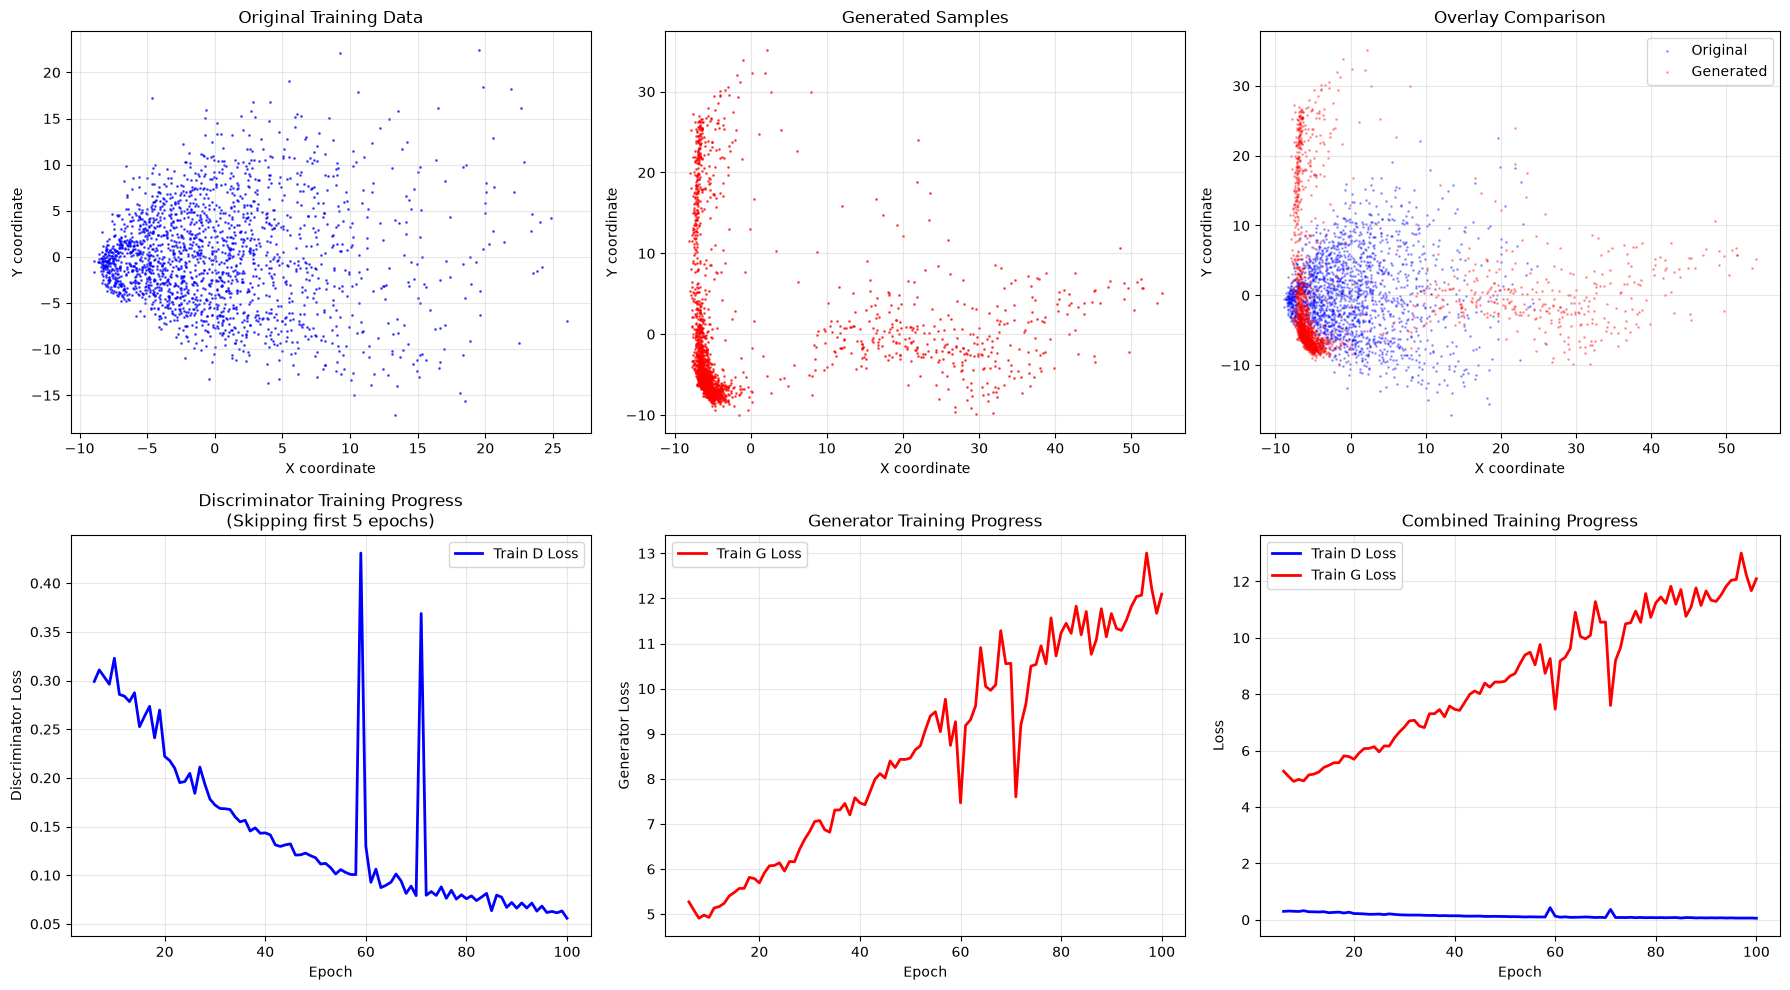

📈 Epoch 100 Summary:
   Train D Loss: 0.0558, Val D Loss: 0.0820
   Train G Loss: 12.0955, Val G Loss: 13.1267

🎉 Training completed!

🎨 Final comprehensive visualization:


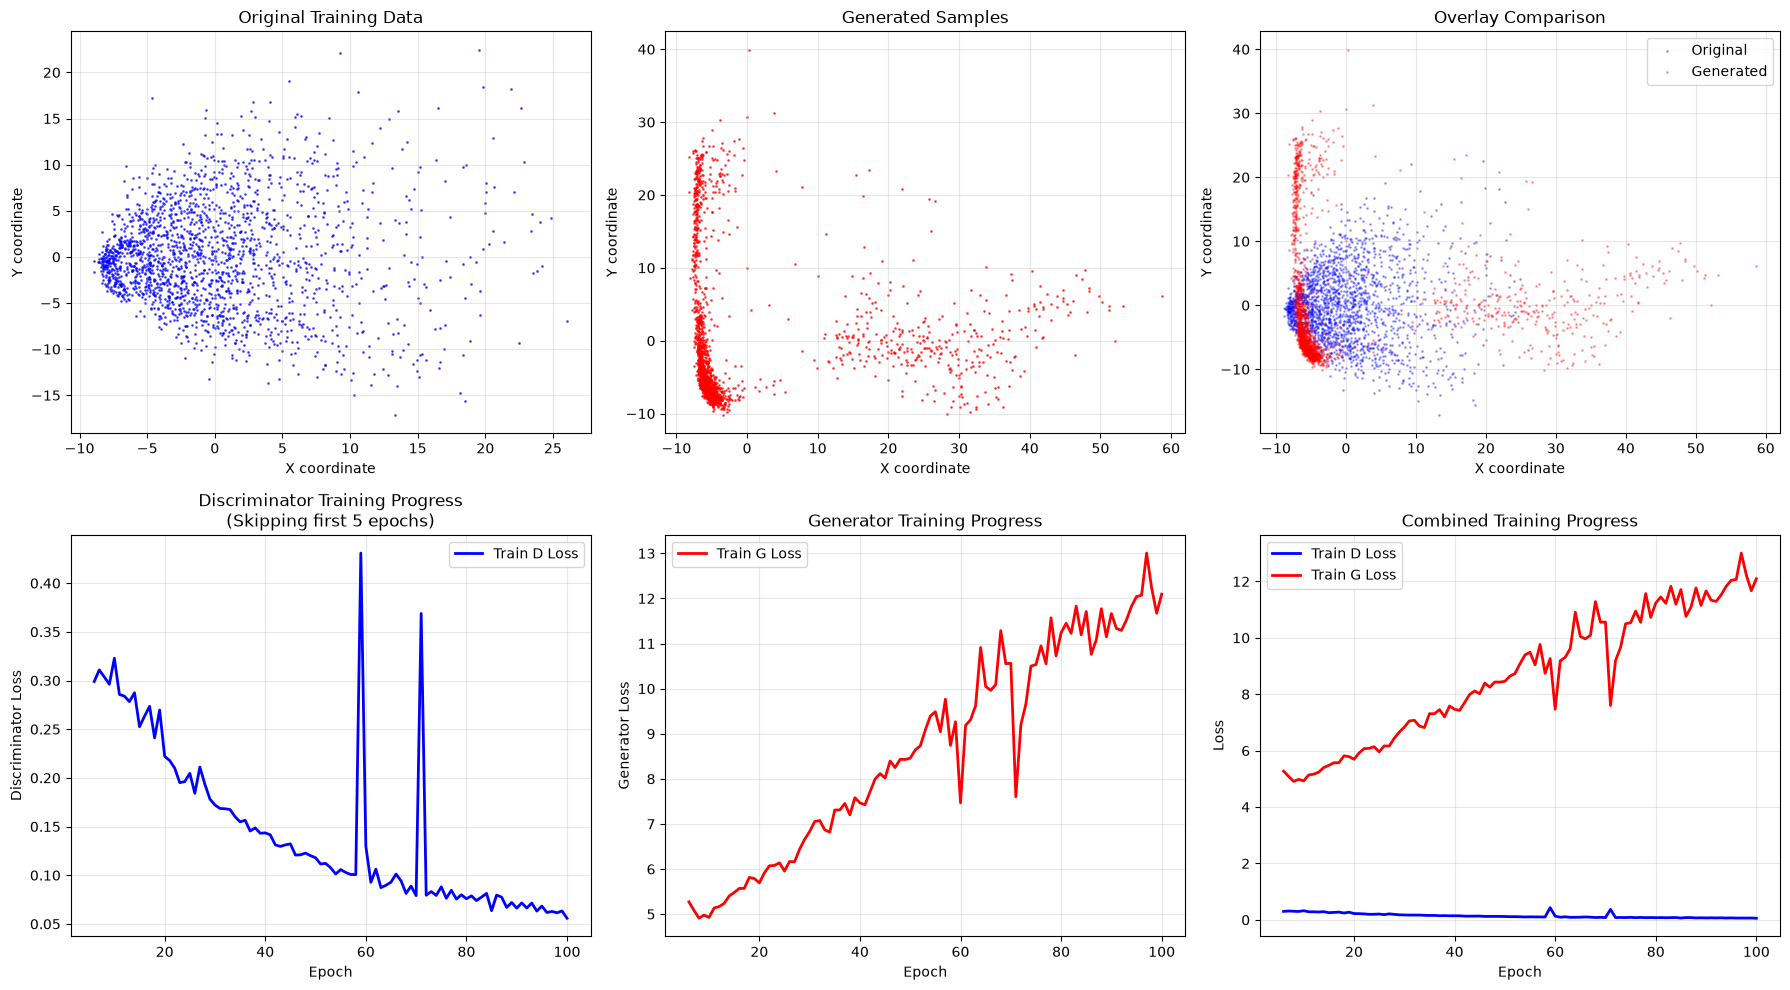

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


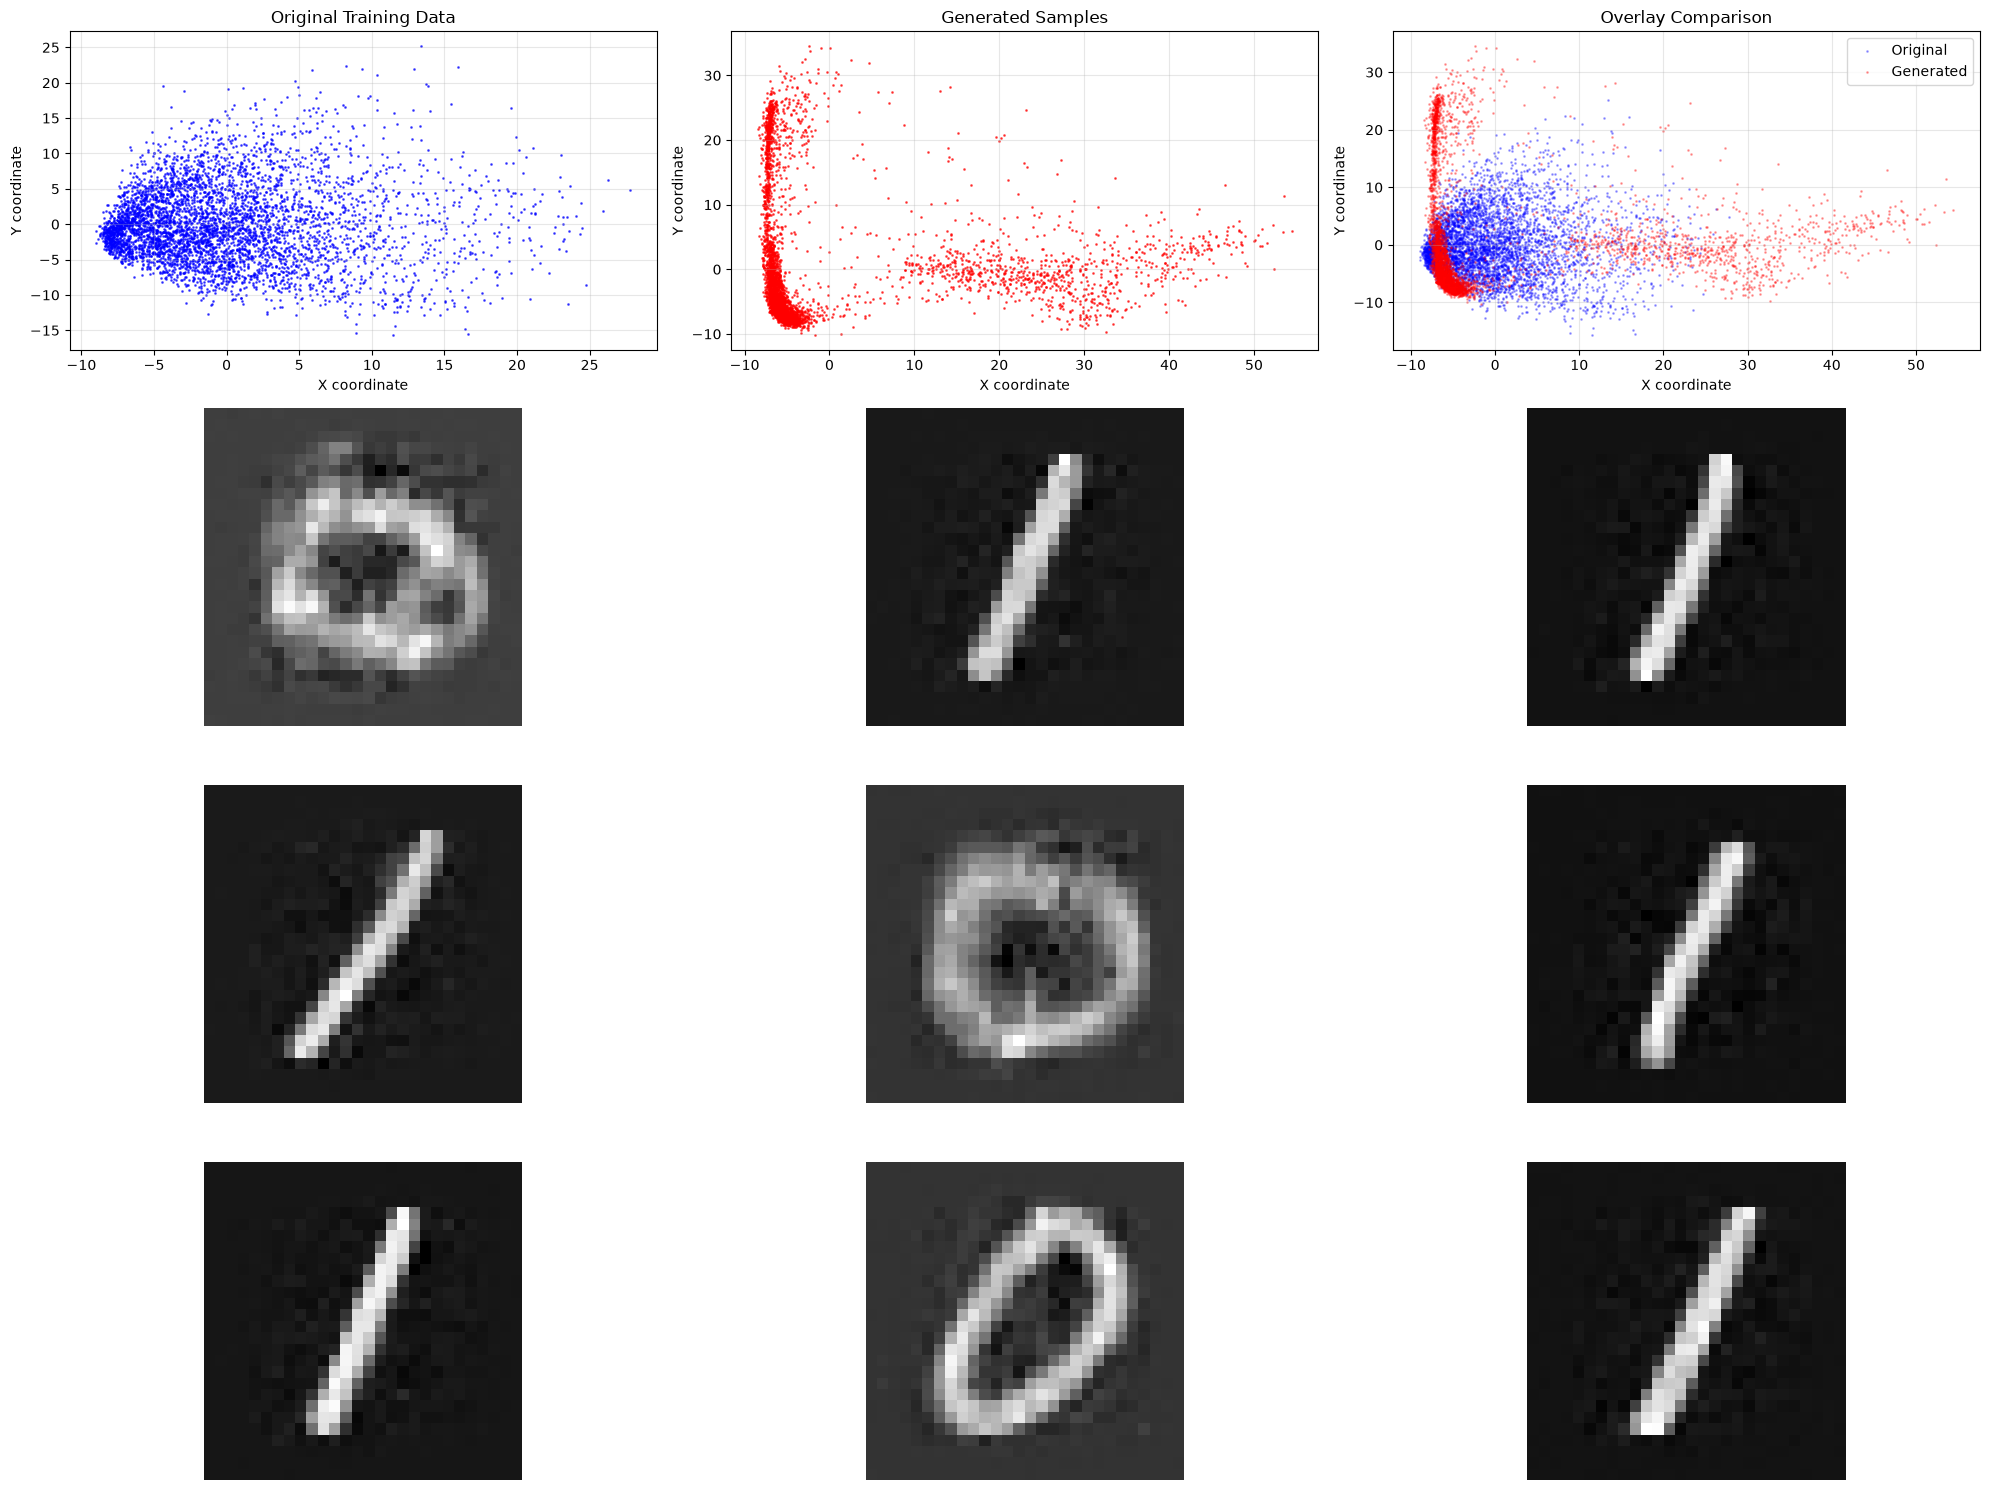

In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = torch.from_numpy(train_data[:100]).to(device).float()
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
